# RF-DETR Weight-Sharing NAS – Google Colab Runner

Notebook điều phối để kéo code từ GitHub về Google Colab (GPU **L4**), cài đặt package `rfdetr_reproduction`, và chạy toàn bộ 3 giai đoạn reproduction + **thí nghiệm cải tiến A/B (PAB-NAS / Sandwich)** với **checkpoint & kết quả đồng bộ trực tiếp với cấu trúc Google Drive hiện có**:

```text
/content/drive/MyDrive/RFDETR_Checkpoints/
├── nas_supernet_cocoinit_full.pth          (checkpoint Baseline Uniform Epoch 20 có sẵn)
├── nas_train_history.csv
├── project_checkpoints/nas/
│   ├── nas_supernet_latest.pth             (symlink tới bản Uniform)
│   ├── nas_supernet_ema_only.pth
│   ├── nas_supernet_pab_nas_latest.pth     (checkpoint cải tiến tách riêng, không ghi đè)
│   └── nas_supernet_pab_nas_ema_only.pth
└── results_cocoinit/                       (thư mục lưu kết quả & biểu đồ)
    ├── nas/
    ├── diagnostics/
    ├── grid_search/
    ├── deployment/
    └── baselines/
```


## 1. Mount Google Drive & Pull/Clone Code từ GitHub


In [2]:
import os
import subprocess
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

# === CẤU HÌNH REPO GITHUB CỦA BẠN ===
GITHUB_REPO_URL = "https://github.com/MTri1172006/RF-DETR-Reproduction"  # <-- Điền link repo của bạn
BRANCH = "main"
USE_PRIVATE_TOKEN = False  # Đổi thành True nếu repo private (lưu PAT vào Colab Secrets tên GITHUB_TOKEN)

REPO_DIR = Path("/content/RF-DETR-Reproduction")

repo_url = GITHUB_REPO_URL
if USE_PRIVATE_TOKEN:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    repo_url = GITHUB_REPO_URL.replace("https://", f"https://{token}@")

if (REPO_DIR / ".git").exists():
    print(f"Repo đã tồn tại tại {REPO_DIR} -> chạy git pull ({BRANCH})...")
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin"], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "checkout", BRANCH], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "origin", BRANCH], check=True)
else:
    print(f"Cloning {GITHUB_REPO_URL} (branch={BRANCH}) -> {REPO_DIR} ...")
    subprocess.run(["git", "clone", "-b", BRANCH, repo_url, str(REPO_DIR)], check=True)

os.chdir(REPO_DIR)
print("Working directory:", os.getcwd())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning https://github.com/MTri1172006/RF-DETR-Reproduction (branch=main) -> /content/RF-DETR-Reproduction ...
Working directory: /content/RF-DETR-Reproduction


## 2. Cài đặt thư viện, Package `rfdetr_reproduction` & Chạy Unit Tests


In [3]:
!pip install -q "rfdetr[train,loggers] @ git+https://github.com/roboflow/rf-detr.git@382607f3d7ecbf513b991a8ee9f1a3abe3a340f0"
!pip install -q pycocotools onnx onnxruntime-gpu ultralytics pytest tqdm
!pip install -q -e .

# Chạy unit test kiểm tra validator, search space (111 / 3948 / 3780), dataset & PAB-NAS sampler
!pytest -v


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for rfdetr-reproduction (pyproject.toml) ... done
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/RF-DETR-Reproduction
configfile: pyproject.toml
testpaths: tests
plugins: langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0, platformdirs-4.14.3
collected 17 items                                                             

tests/test_dataset.py::TestVOCDatasetConversionAndValidation::test_deterministic_split_and_zero_overlap PASSED [  5%]
tests/test_dataset.py::TestVOCDatasetCon

## 3. Ánh xạ cấu trúc Google Drive hiện có (`RFDETR_Checkpoints`) vào Project

Cell này tự động:
1. Trỏ `RFDETR_DATA_DIR` về SSD local của Colab (`/content/data`) để đọc ảnh nhanh nhất.
2. Trỏ `RFDETR_CKPT_DIR` và `RFDETR_OUTPUT_DIR` thẳng vào `/content/drive/MyDrive/RFDETR_Checkpoints/`.
3. **Liên kết tự động checkpoint sẵn có** `nas_supernet_cocoinit_full.pth` → `nas/nas_supernet_latest.pth` và tách sẵn `nas/nas_supernet_ema_only.pth` (nhẹ hơn cho Grid Search & Export) để mọi script nhận ngay trọng số Epoch 20 mà không phải train lại từ đầu.
4. **Liên kết tự động các file kết quả cũ** (`nas_validation_results_cocoinit.csv`, `pareto_frontier_cocoinit.csv`, `nas_train_history.csv`) vào thư mục đích để có thể resume mượt mà.


In [4]:
import os
import shutil
from pathlib import Path
import torch

DRIVE_ROOT = Path("/content/drive/MyDrive/RFDETR_Checkpoints")
DRIVE_RESULTS = DRIVE_ROOT / "results_cocoinit"
DRIVE_FULL_CKPT = DRIVE_ROOT / "nas_supernet_cocoinit_full.pth"

# Thư mục runtime chuẩn cho các script trong project
DATA_DIR = Path("/content/data")
CKPT_DIR = DRIVE_ROOT / "project_checkpoints"
OUTPUT_DIR = DRIVE_RESULTS

os.environ["RFDETR_DATA_DIR"] = str(DATA_DIR)
os.environ["RFDETR_CKPT_DIR"] = str(CKPT_DIR)
os.environ["RFDETR_OUTPUT_DIR"] = str(OUTPUT_DIR)

for d in [
    DATA_DIR,
    CKPT_DIR / "nas",
    CKPT_DIR / "pretrained",
    CKPT_DIR / "diagnostics",
    OUTPUT_DIR / "nas",
    OUTPUT_DIR / "diagnostics",
    OUTPUT_DIR / "grid_search",
    OUTPUT_DIR / "deployment",
    OUTPUT_DIR / "baselines",
]:
    d.mkdir(parents=True, exist_ok=True)


def _link_or_copy(src: Path, dst: Path):
    if not src.exists() or dst.exists():
        return
    try:
        os.symlink(src, dst)
        print(f"[Symlink] {dst.name} -> {src}")
    except OSError:
        shutil.copy2(src, dst)
        print(f"[Copy]    {src} -> {dst}")


# 1. Liên kết checkpoint Epoch 20 sẵn có vào chuẩn project
nas_latest = CKPT_DIR / "nas" / "nas_supernet_latest.pth"
nas_ema = CKPT_DIR / "nas" / "nas_supernet_ema_only.pth"

if DRIVE_FULL_CKPT.exists():
    _link_or_copy(DRIVE_FULL_CKPT, nas_latest)
    if not nas_ema.exists():
        print("Đang tách bản nhẹ nas_supernet_ema_only.pth từ nas_supernet_cocoinit_full.pth ...")
        ckpt = torch.load(DRIVE_FULL_CKPT, map_location="cpu", weights_only=False)
        torch.save(
            {
                "epoch": ckpt.get("epoch", 20),
                "ema_model": ckpt.get("ema_model", ckpt.get("model")),
                "ema_updates": ckpt.get("ema_updates", 0),
                "provenance": ckpt.get("provenance"),
            },
            nas_ema,
        )
        del ckpt
        print(f"[Created] {nas_ema} ({nas_ema.stat().st_size / 1e6:.1f} MB)")
else:
    print(f"[INFO] Không tìm thấy {DRIVE_FULL_CKPT} -> sẽ train mới khi chạy Stage 1.")

# 2. Liên kết các file kết quả đã có trên Drive để resume Grid Search / Deployment
_link_or_copy(DRIVE_RESULTS / "nas_validation_results_cocoinit.csv", OUTPUT_DIR / "grid_search" / "nas_validation_results.csv")
_link_or_copy(DRIVE_RESULTS / "pareto_frontier_cocoinit.csv", OUTPUT_DIR / "grid_search" / "pareto_frontier.csv")
_link_or_copy(DRIVE_RESULTS / "rfdetr_nas_supernet" / "nas_train_history.csv", OUTPUT_DIR / "nas" / "nas_train_history.csv")

print("\n=== TRẠNG THÁI ĐƯỜNG DẪN ===")
print("RFDETR_DATA_DIR  =", os.environ["RFDETR_DATA_DIR"])
print("RFDETR_CKPT_DIR  =", os.environ["RFDETR_CKPT_DIR"])
print("RFDETR_OUTPUT_DIR=", os.environ["RFDETR_OUTPUT_DIR"])
print("Latest ckpt      =", nas_latest.exists(), f"({nas_latest})")
print("EMA-only ckpt    =", nas_ema.exists(), f"({nas_ema})")



=== TRẠNG THÁI ĐƯỜNG DẪN ===
RFDETR_DATA_DIR  = /content/data
RFDETR_CKPT_DIR  = /content/drive/MyDrive/RFDETR_Checkpoints/project_checkpoints
RFDETR_OUTPUT_DIR= /content/drive/MyDrive/RFDETR_Checkpoints/results_cocoinit
Latest ckpt      = True (/content/drive/MyDrive/RFDETR_Checkpoints/project_checkpoints/nas/nas_supernet_latest.pth)
EMA-only ckpt    = True (/content/drive/MyDrive/RFDETR_Checkpoints/project_checkpoints/nas/nas_supernet_ema_only.pth)


## 4. Giai đoạn 1 – Kiểm tra môi trường, Chuẩn bị VOC2007 & Huấn luyện NAS (Baseline Uniform)


In [5]:
# 4.1. Ghi provenance (GPU L4, CUDA, PyTorch, Git SHA) -> results_cocoinit/provenance.json
!python scripts/setup_environment.py --require-cuda

# 4.2. Tải VOC2007 & chuyển sang COCO JSON (lọc difficult=1, kiểm tra zero-overlap)
!python scripts/prepare_dataset.py


[2026-11-26 09:06:26] [INFO] rfdetr_reproduction.environment.provenance: Recorded environment provenance -> /content/drive/MyDrive/RFDETR_Checkpoints/results_cocoinit/provenance.json
{
  "recorded_at": "2026-11-26T09:06:25",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "seed": 42,
  "git_branch": "main",
  "git_commit": "efecea7d98e5aa99319158ae8b9b68ae78a72849",
  "rfdetr_pinned_commit": "382607f3d7ecbf513b991a8ee9f1a3abe3a340f0",
  "pytorch": "2.14.1+cu130",
  "cuda": "13.0",
  "cuda_available": true,
  "gpu": "NVIDIA L4",
  "vram_gb": 22.03,
  "bf16_supported": true,
  "packages": {
    "torch": "2.14.1+cu130",
    "torchvision": "0.29.1+cu130",
    "rfdetr": "1.13.0.dev0",
    "pycocotools": "2.0.11",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0",
    "Pillow": "11.3.0",
    "onnx": "1.23.2",
    "onnxruntime-gpu": "1.32.0",
    "ultralytics": "8.4.219"
  }
}
100% 460M/460M [00:20<00:00, 22.0MB/s]
100% 451M/451M [00:38<00:

In [6]:
# 4.3. Huấn luyện Weight-Sharing NAS Supernet (Baseline Uniform)
# Mặc định đặt False vì bạn đã có sẵn nas_supernet_cocoinit_full.pth (Epoch 20) trên Drive.
RUN_TRAIN_NAS = False
NAS_EPOCHS = 20

if RUN_TRAIN_NAS:
    !python scripts/train_nas.py --sampling-strategy uniform --epochs {NAS_EPOCHS}
    if not DRIVE_FULL_CKPT.is_symlink() and (CKPT_DIR / "nas" / "nas_supernet_latest.pth").exists():
        shutil.copy2(CKPT_DIR / "nas" / "nas_supernet_latest.pth", DRIVE_FULL_CKPT)
    hist_src = OUTPUT_DIR / "nas" / "nas_train_history.csv"
    if hist_src.exists():
        shutil.copy2(hist_src, DRIVE_ROOT / "nas_train_history.csv")
        (DRIVE_RESULTS / "rfdetr_nas_supernet").mkdir(parents=True, exist_ok=True)
        shutil.copy2(hist_src, DRIVE_RESULTS / "rfdetr_nas_supernet" / "nas_train_history.csv")
else:
    print("Bỏ qua train_nas.py (đang dùng sẵn checkpoint Baseline Uniform Epoch 20 trên Drive).")


Bỏ qua train_nas.py (đang dùng sẵn checkpoint Baseline Uniform Epoch 20 trên Drive).


## 5. Giai đoạn 2 – Thí nghiệm Chẩn đoán (Gradient Conflict, Hypo 1, Hypo 2) & Grid Search


In [7]:
# 5a. Gradient Conflict Diagnosis (Mục 5b)
from IPython.display import Image, display
import pandas as pd

RUN_GRADIENT_CONFLICT = False
GC_TAG = "ep20"

if RUN_GRADIENT_CONFLICT:
    !python scripts/run_gradient_conflict.py --checkpoint "{DRIVE_FULL_CKPT}" --tag {GC_TAG}
    img_gc = OUTPUT_DIR / "diagnostics" / f"gradient_conflict_heatmap_{GC_TAG}.png"
    csv_gc = OUTPUT_DIR / "diagnostics" / f"gradient_conflict_summary_{GC_TAG}.csv"
    if csv_gc.exists():
        display(pd.read_csv(csv_gc).round(4))
    if img_gc.exists():
        display(Image(filename=str(img_gc)))


In [8]:
# 5b. Hypothesis 1 – Tốc độ hội tụ riêng của từng Architecture (Mục 5d)
# Tự động lưu & resume trạng thái qua project_checkpoints/diagnostics/hypo1_state.pth trên Drive
RUN_HYPO1 = False
HYPO1_EPOCHS = 20
HYPO1_EVAL_EVERY = 2

if RUN_HYPO1:
    !python scripts/run_hypothesis1.py --epochs {HYPO1_EPOCHS} --eval-every {HYPO1_EVAL_EVERY}
    csv_h1 = OUTPUT_DIR / "diagnostics" / "hypo1_t90_summary.csv"
    img_h1 = OUTPUT_DIR / "diagnostics" / "hypo1_convergence.png"
    if csv_h1.exists():
        display(pd.read_csv(csv_h1).round(4))
    if img_h1.exists():
        display(Image(filename=str(img_h1)))


In [9]:
# 5c. Hypothesis 2 – Weight Drift / Interference trên mạng nhỏ khi tăng p(A) (Mục 5e)
# Nạp trực tiếp từ nas_supernet_cocoinit_full.pth (không ghi đè checkpoint gốc)
RUN_HYPO2 = False
HYPO2_EXTRA_EPOCHS = 5

if RUN_HYPO2:
    !python scripts/run_hypothesis2.py --ckpt "{DRIVE_FULL_CKPT}" --extra-epochs {HYPO2_EXTRA_EPOCHS}
    csv_h2 = OUTPUT_DIR / "diagnostics" / "hypo2_summary.csv"
    img_h2 = OUTPUT_DIR / "diagnostics" / "hypo2_interference.png"
    if csv_h2.exists():
        display(pd.read_csv(csv_h2).round(4))
    if img_h2.exists():
        display(Image(filename=str(img_h2)))


In [10]:
# 5d. Post-Training Grid Search & Pareto Frontier (Baseline Uniform – Mục 6)
RUN_GRID_SEARCH = False
GRID_MODE = "representative"  # "representative" | "full"

if RUN_GRID_SEARCH:
    !python scripts/run_grid_search.py --mode {GRID_MODE} --checkpoint "{CKPT_DIR / 'nas' / 'nas_supernet_ema_only.pth'}"
    pareto_csv = OUTPUT_DIR / "grid_search" / "pareto_frontier.csv"
    pareto_png = OUTPUT_DIR / "grid_search" / "nas_pareto_frontier.png"
    if pareto_csv.exists():
        display(pd.read_csv(pareto_csv))
    if pareto_png.exists():
        display(Image(filename=str(pareto_png)))
else:
    print("Bỏ qua Grid Search Baseline (đã có sẵn pareto_frontier_cocoinit.csv trên Drive).")


Bỏ qua Grid Search Baseline (đã có sẵn pareto_frontier_cocoinit.csv trên Drive).


## 6. Giai đoạn 3 – Deployment (ONNX/TensorRT/Throttling), YOLO Baselines & Segmentation


In [11]:
RUN_DEPLOYMENT = False
RUN_BASELINES = False
RUN_SEGMENTATION = False

EMA_CKPT = CKPT_DIR / "nas" / "nas_supernet_ema_only.pth"
PARETO_CSV = OUTPUT_DIR / "grid_search" / "pareto_frontier.csv"

if RUN_DEPLOYMENT:
    !python scripts/run_deployment.py --ckpt "{EMA_CKPT}" --pareto-csv "{PARETO_CSV}"
    thr_png = OUTPUT_DIR / "deployment" / "throttling_comparison.png"
    if thr_png.exists():
        display(Image(filename=str(thr_png)))

if RUN_BASELINES:
    !python scripts/run_baselines.py --ckpt "{EMA_CKPT}" --pareto-csv "{PARETO_CSV}" --epochs 20
    comp_csv = OUTPUT_DIR / "baselines" / "fair_baseline_comparison_test.csv"
    if comp_csv.exists():
        display(pd.read_csv(comp_csv))

if RUN_SEGMENTATION:
    !python scripts/run_segmentation.py --enable


## 7. Cải tiến Phương pháp (PAB-NAS / Sandwich Micro-Batching) & Đối chứng A/B

Chạy trên **cùng điều kiện** với Baseline Uniform (`SEED=42`, COCO-init, 20 epochs trên VOC2007) và lưu tách biệt hoàn toàn theo `PAB_EXP_TAG` (không ghi đè checkpoint hay CSV của Baseline):
- `PAB_STRATEGY = "pruned_anchor"` → cắt tỉa `p=32, w=4` + 2 giai đoạn với ngân sách mỏ neo ~32% cho mạng nhỏ.
- `PAB_STRATEGY = "sandwich"` → thêm Sandwich Micro-Batching trên 4 micro-steps (`1 lớn + 1 nhỏ + 2 lõi`).


In [16]:
# 7.1. Huấn luyện siêu mạng cải tiến (tự động resume từ Drive nếu Colab ngắt giữa chừng)
from IPython.display import Image, display
import pandas as pd

PAB_STRATEGY = "sandwich"   # Đổi thành "sandwich" nếu muốn chạy bản Sandwich Micro-Batching
PAB_EXP_TAG = "sandwich_nas"          # Gợi ý: "pab_nas" cho pruned_anchor, "sandwich_nas" cho sandwich
PAB_EPOCHS = 20

RUN_PAB_TRAIN = True
RUN_PAB_GC = True
RUN_PAB_GRID_SEARCH = True

PAB_LATEST_CKPT = CKPT_DIR / "nas" / f"nas_supernet_{PAB_EXP_TAG}_latest.pth"
PAB_EMA_CKPT = CKPT_DIR / "nas" / f"nas_supernet_{PAB_EXP_TAG}_ema_only.pth"

if RUN_PAB_TRAIN:
    !python scripts/train_nas.py --sampling-strategy {PAB_STRATEGY} --exp-tag {PAB_EXP_TAG} --epochs {PAB_EPOCHS}
    pab_hist_csv = OUTPUT_DIR / "nas" / f"nas_train_history_{PAB_EXP_TAG}.csv"
    if pab_hist_csv.exists():
        display(pd.read_csv(pab_hist_csv).tail(5))


[2026-11-26 10:55:36] [INFO] rfdetr_reproduction.training.trainer: Initialized NAS sampler: {'strategy': 'sandwich', 'all_configs': 111, 'pruned_configs': 28, 'anchor_configs': 8, 'core_configs': 8, 'large_anchors': 4, 'small_anchors': 4, 'phase1_epochs': 8, 'core_prob': 0.68}
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pydantic/main.py:280: PretrainWeightsCompatibilityWarning: RFDETRBaseConfig was instantiated with pretrain_weights=None. The model will be initialised from scratch, which typically produces lower accuracy than fine-tuning from the published checkpoint ('rf-detr-base.pth').
  validated_self = self.__pydantic_val

,epoch,train_loss,unique_nas_configs_sampled,peak_vram_gb,elapsed_sec
15,16,7.011797,12,2.50,206.3
16,17,7.002883,12,2.49,206.9
17,18,6.973688,12,2.49,207.5
18,19,6.956033,12,2.50,207.1
19,20,7.274063,12,2.50,206.3


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pydantic/main.py:280: PretrainWeightsCompatibilityWarning: RFDETRBaseConfig was instantiated with pretrain_weights=None. The model will be initialised from scratch, which typically produces lower accuracy than fine-tuning from the published checkpoint ('rf-detr-base.pth').
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)
[2026-11-26 12:08:25] [INFO] rfdetr_reproduction.training.checkpoint: Loaded NAS checkpoint from /content/drive/MyDrive/RFDETR_Checkpoints/project_checkpoints/nas/nas_supernet_sandwich_nas_latest.pth (epoch=20)
[2026-11-26 12:0

,group,mean_cos_between_subnets,min_cos_between_subnets,pct_pairs_negative,mean_cos_anchor_vs_others,batch_noise_baseline(self_cos),grad_norm_cv
0,patch_embed,0.0509,-0.0929,23.8095,0.0712,0.0379,0.6239
1,backbone,0.0627,-0.0084,4.7619,0.1191,0.0072,0.5419
2,decoder,0.0773,-0.0536,28.5714,0.1387,0.0255,1.3520
3,other_head,0.2181,-0.0090,4.7619,0.3239,0.0133,0.9917


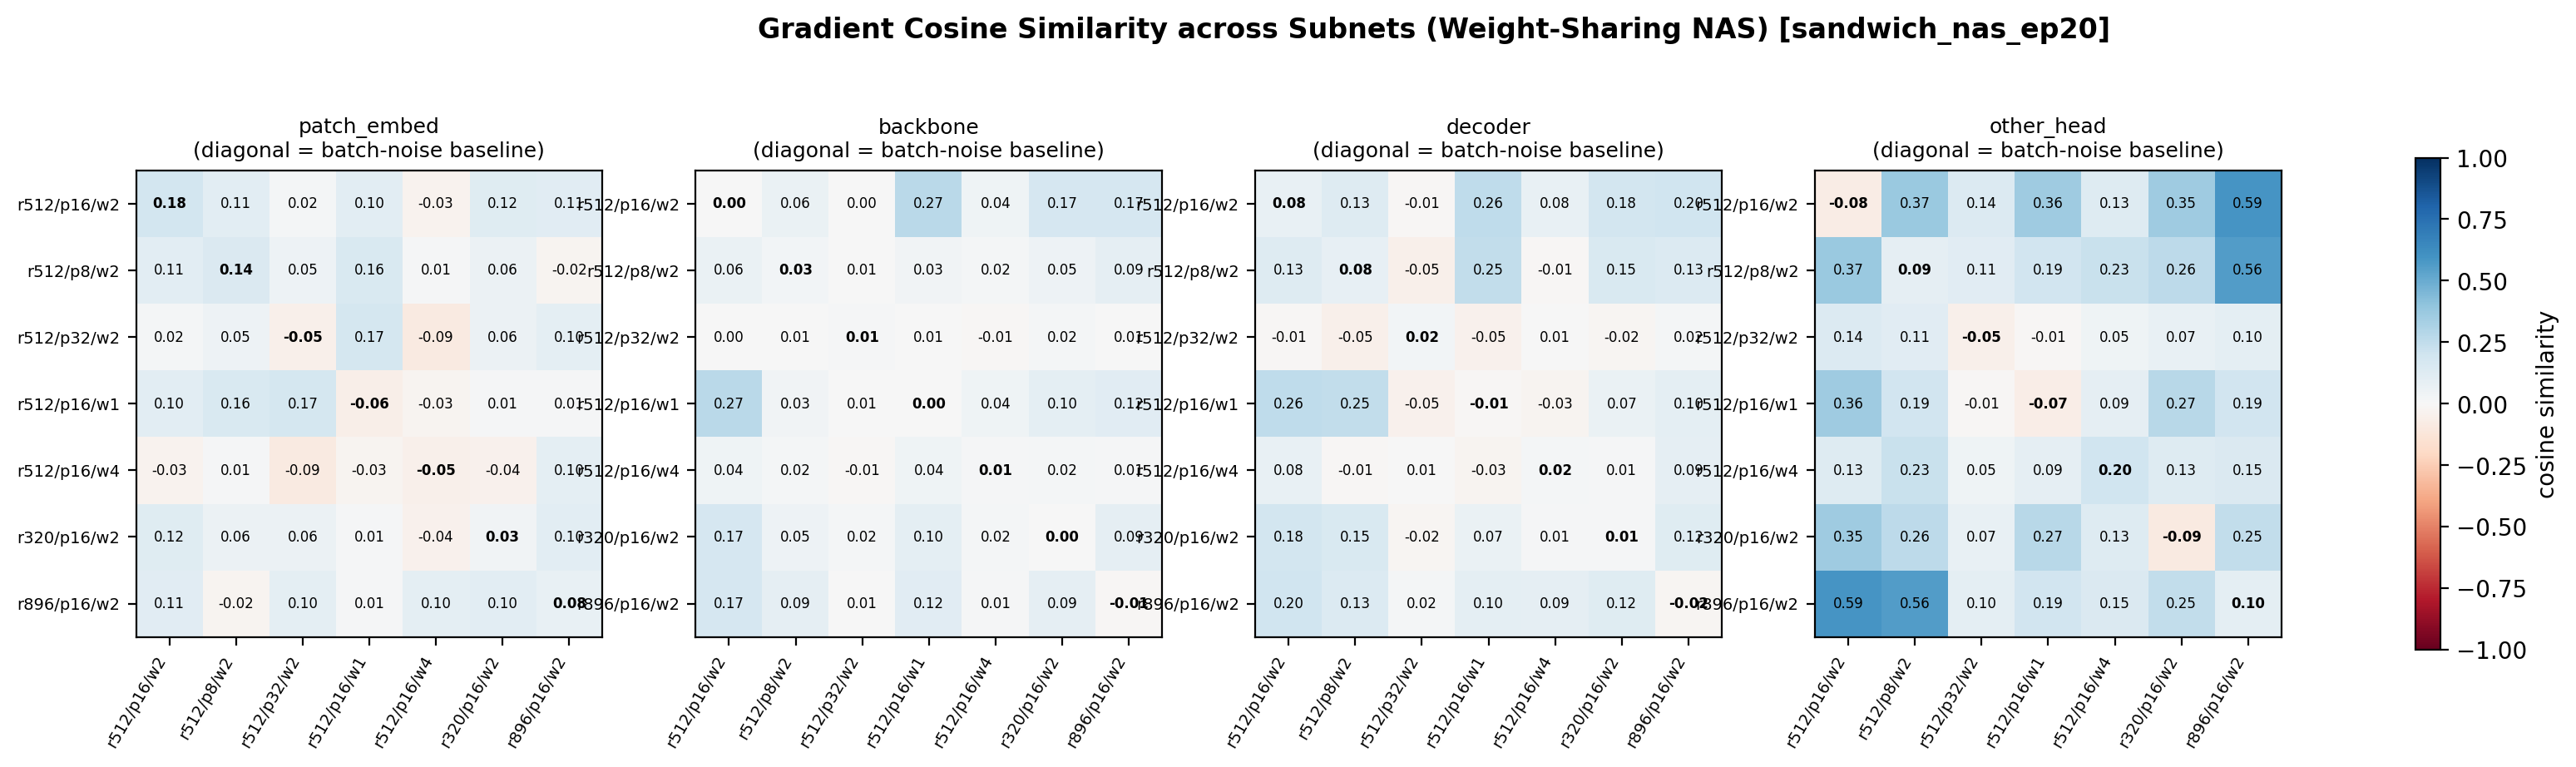

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pydantic/main.py:280: PretrainWeightsCompatibilityWarning: RFDETRBaseConfig was instantiated with pretrain_weights=None. The model will be initialised from scratch, which typically produces lower accuracy than fine-tuning from the published checkpoint ('rf-detr-base.pth').
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)
[2026-11-26 12:08:51] [INFO] rfdetr_reproduction.training.checkpoint: Loaded EMA weights from /content/drive/MyDrive/RFDETR_Checkpoints/project_checkpoints/nas/nas_supernet_sandwich_nas_ema_only.pth (epoch=20)
[2026-11-26 12:08

,config_id,resolution,patch_size,num_windows,decoder_layers,num_queries,valid,error,latency_median_ms,latency_mean_ms,latency_p90_ms,latency_std_ms,peak_vram_gb,map,map50,ap_s,ap_m,ap_l
0,inference_0032,384,16,2,0,300,True,NaN,16.532266,16.547047,16.916578,0.343619,0.202,0.547102,0.820768,0.340934,0.466850,0.596448
1,inference_0035,384,16,2,1,300,True,NaN,18.874862,19.207723,20.584337,0.970028,0.203,0.574628,0.783090,0.273677,0.451408,0.644613
2,inference_0158,640,16,2,2,300,True,NaN,19.797266,19.810382,20.133454,0.419278,0.235,0.636945,0.816318,0.361378,0.580248,0.683370
3,inference_0164,640,16,2,6,300,True,NaN,27.125013,27.215740,27.496225,0.817051,0.240,0.698335,0.869640,0.394726,0.572359,0.753212


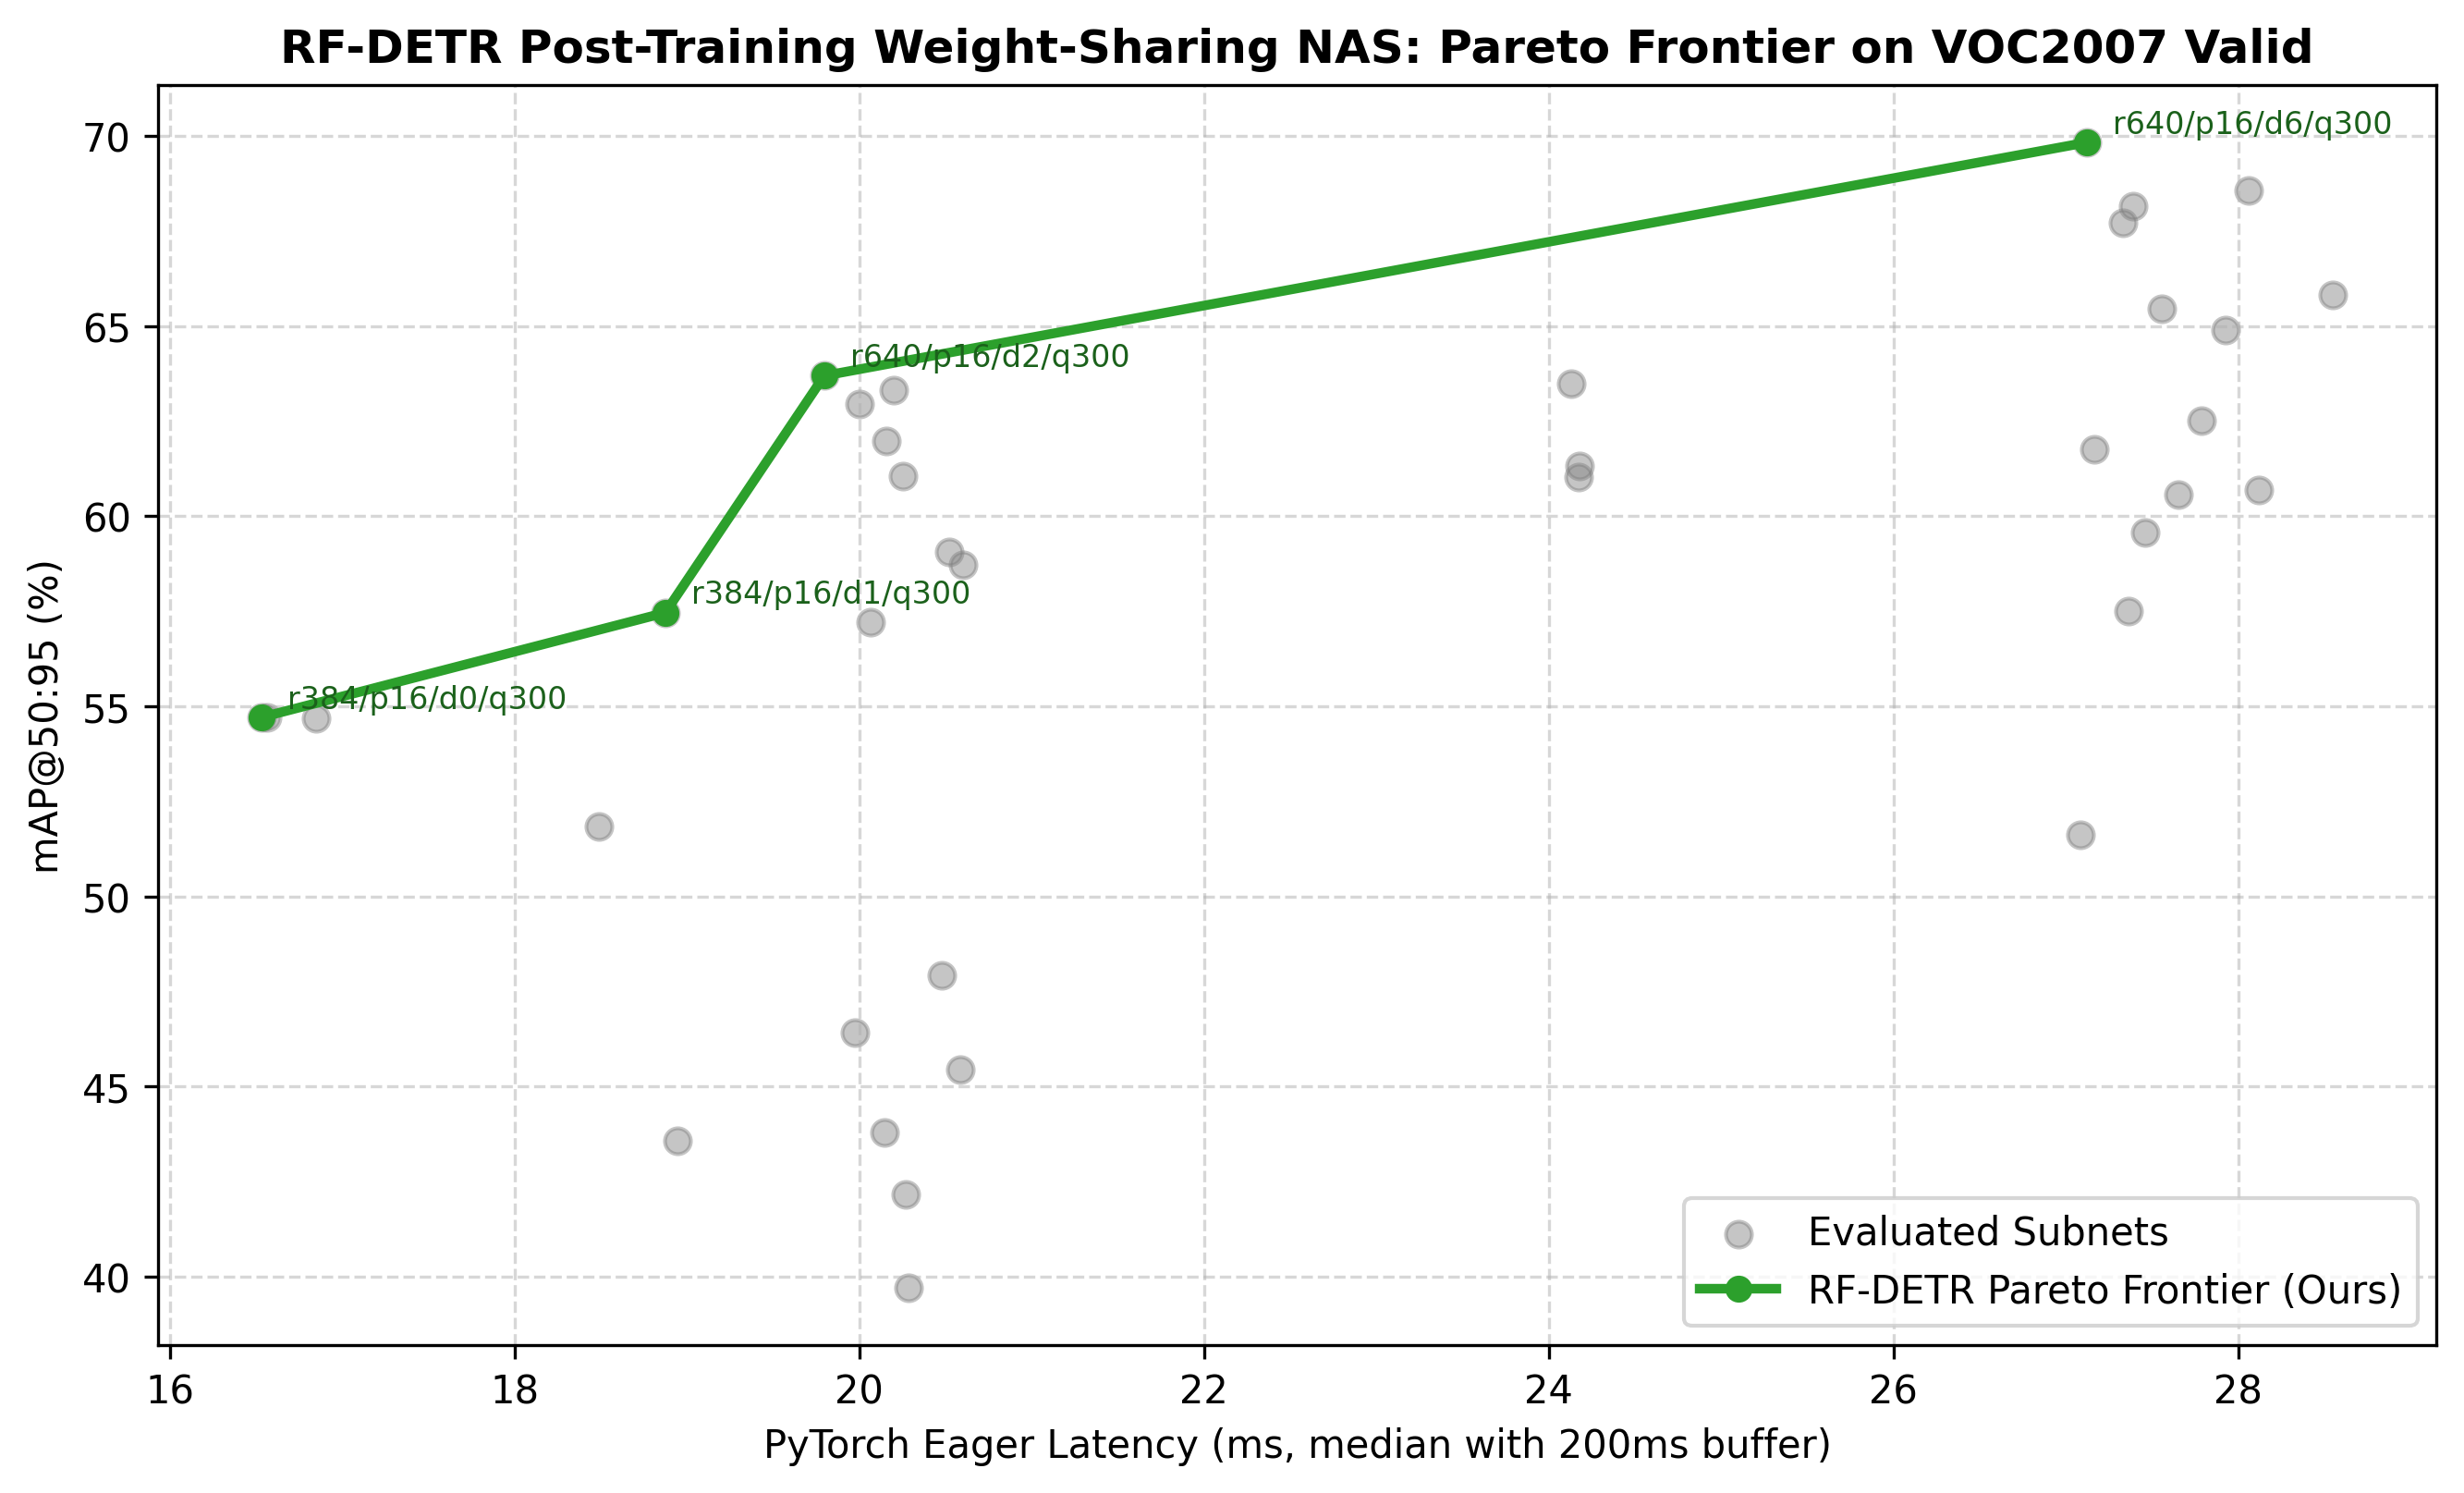

In [18]:
# 7.2. Chẩn đoán Gradient Conflict & Quét lại 37 subnets Pareto cho bản cải tiến
if RUN_PAB_GC:
    assert PAB_LATEST_CKPT.exists(), f"Chưa tìm thấy checkpoint {PAB_LATEST_CKPT}"
    !python scripts/run_gradient_conflict.py --checkpoint "{PAB_LATEST_CKPT}" --tag {PAB_EXP_TAG}_ep{PAB_EPOCHS}
    gc_csv = OUTPUT_DIR / "diagnostics" / f"gradient_conflict_summary_{PAB_EXP_TAG}_ep{PAB_EPOCHS}.csv"
    gc_png = OUTPUT_DIR / "diagnostics" / f"gradient_conflict_heatmap_{PAB_EXP_TAG}_ep{PAB_EPOCHS}.png"
    if gc_csv.exists():
        display(pd.read_csv(gc_csv).round(4))
    if gc_png.exists():
        display(Image(filename=str(gc_png)))

if RUN_PAB_GRID_SEARCH:
    assert PAB_EMA_CKPT.exists(), f"Chưa tìm thấy EMA checkpoint {PAB_EMA_CKPT}"
    !python scripts/run_grid_search.py --mode representative --checkpoint "{PAB_EMA_CKPT}" --exp-tag {PAB_EXP_TAG}
    pab_pareto_csv = OUTPUT_DIR / "grid_search" / f"pareto_frontier_{PAB_EXP_TAG}.csv"
    pab_pareto_png = OUTPUT_DIR / "grid_search" / f"nas_pareto_frontier_{PAB_EXP_TAG}.png"
    if pab_pareto_csv.exists():
        display(pd.read_csv(pab_pareto_csv))
    if pab_pareto_png.exists():
        display(Image(filename=str(pab_pareto_png)))


=== SO SÁNH mAP: BASELINE UNIFORM VS CẢI TIẾN ===


,subnet,uniform_mAP(%),sandwich_nas_mAP(%),delta_mAP(%),uniform_mAP50(%),sandwich_nas_mAP50(%)
0,Tiny (320/p16/w2/d6/q300),62.06,61.76,-0.30,82.55,81.37
1,Nano (384/p16/w2/d6/q300),65.75,65.82,0.07,85.56,84.57
2,Mid (512/p16/w2/d6/q300),69.26,68.56,-0.69,87.35,85.91
3,Peak (640/p16/w2/d6/q300),70.04,69.83,-0.21,87.79,86.96


Thời gian train trung bình/epoch: Uniform = 4.35 phút | sandwich_nas = 3.58 phút


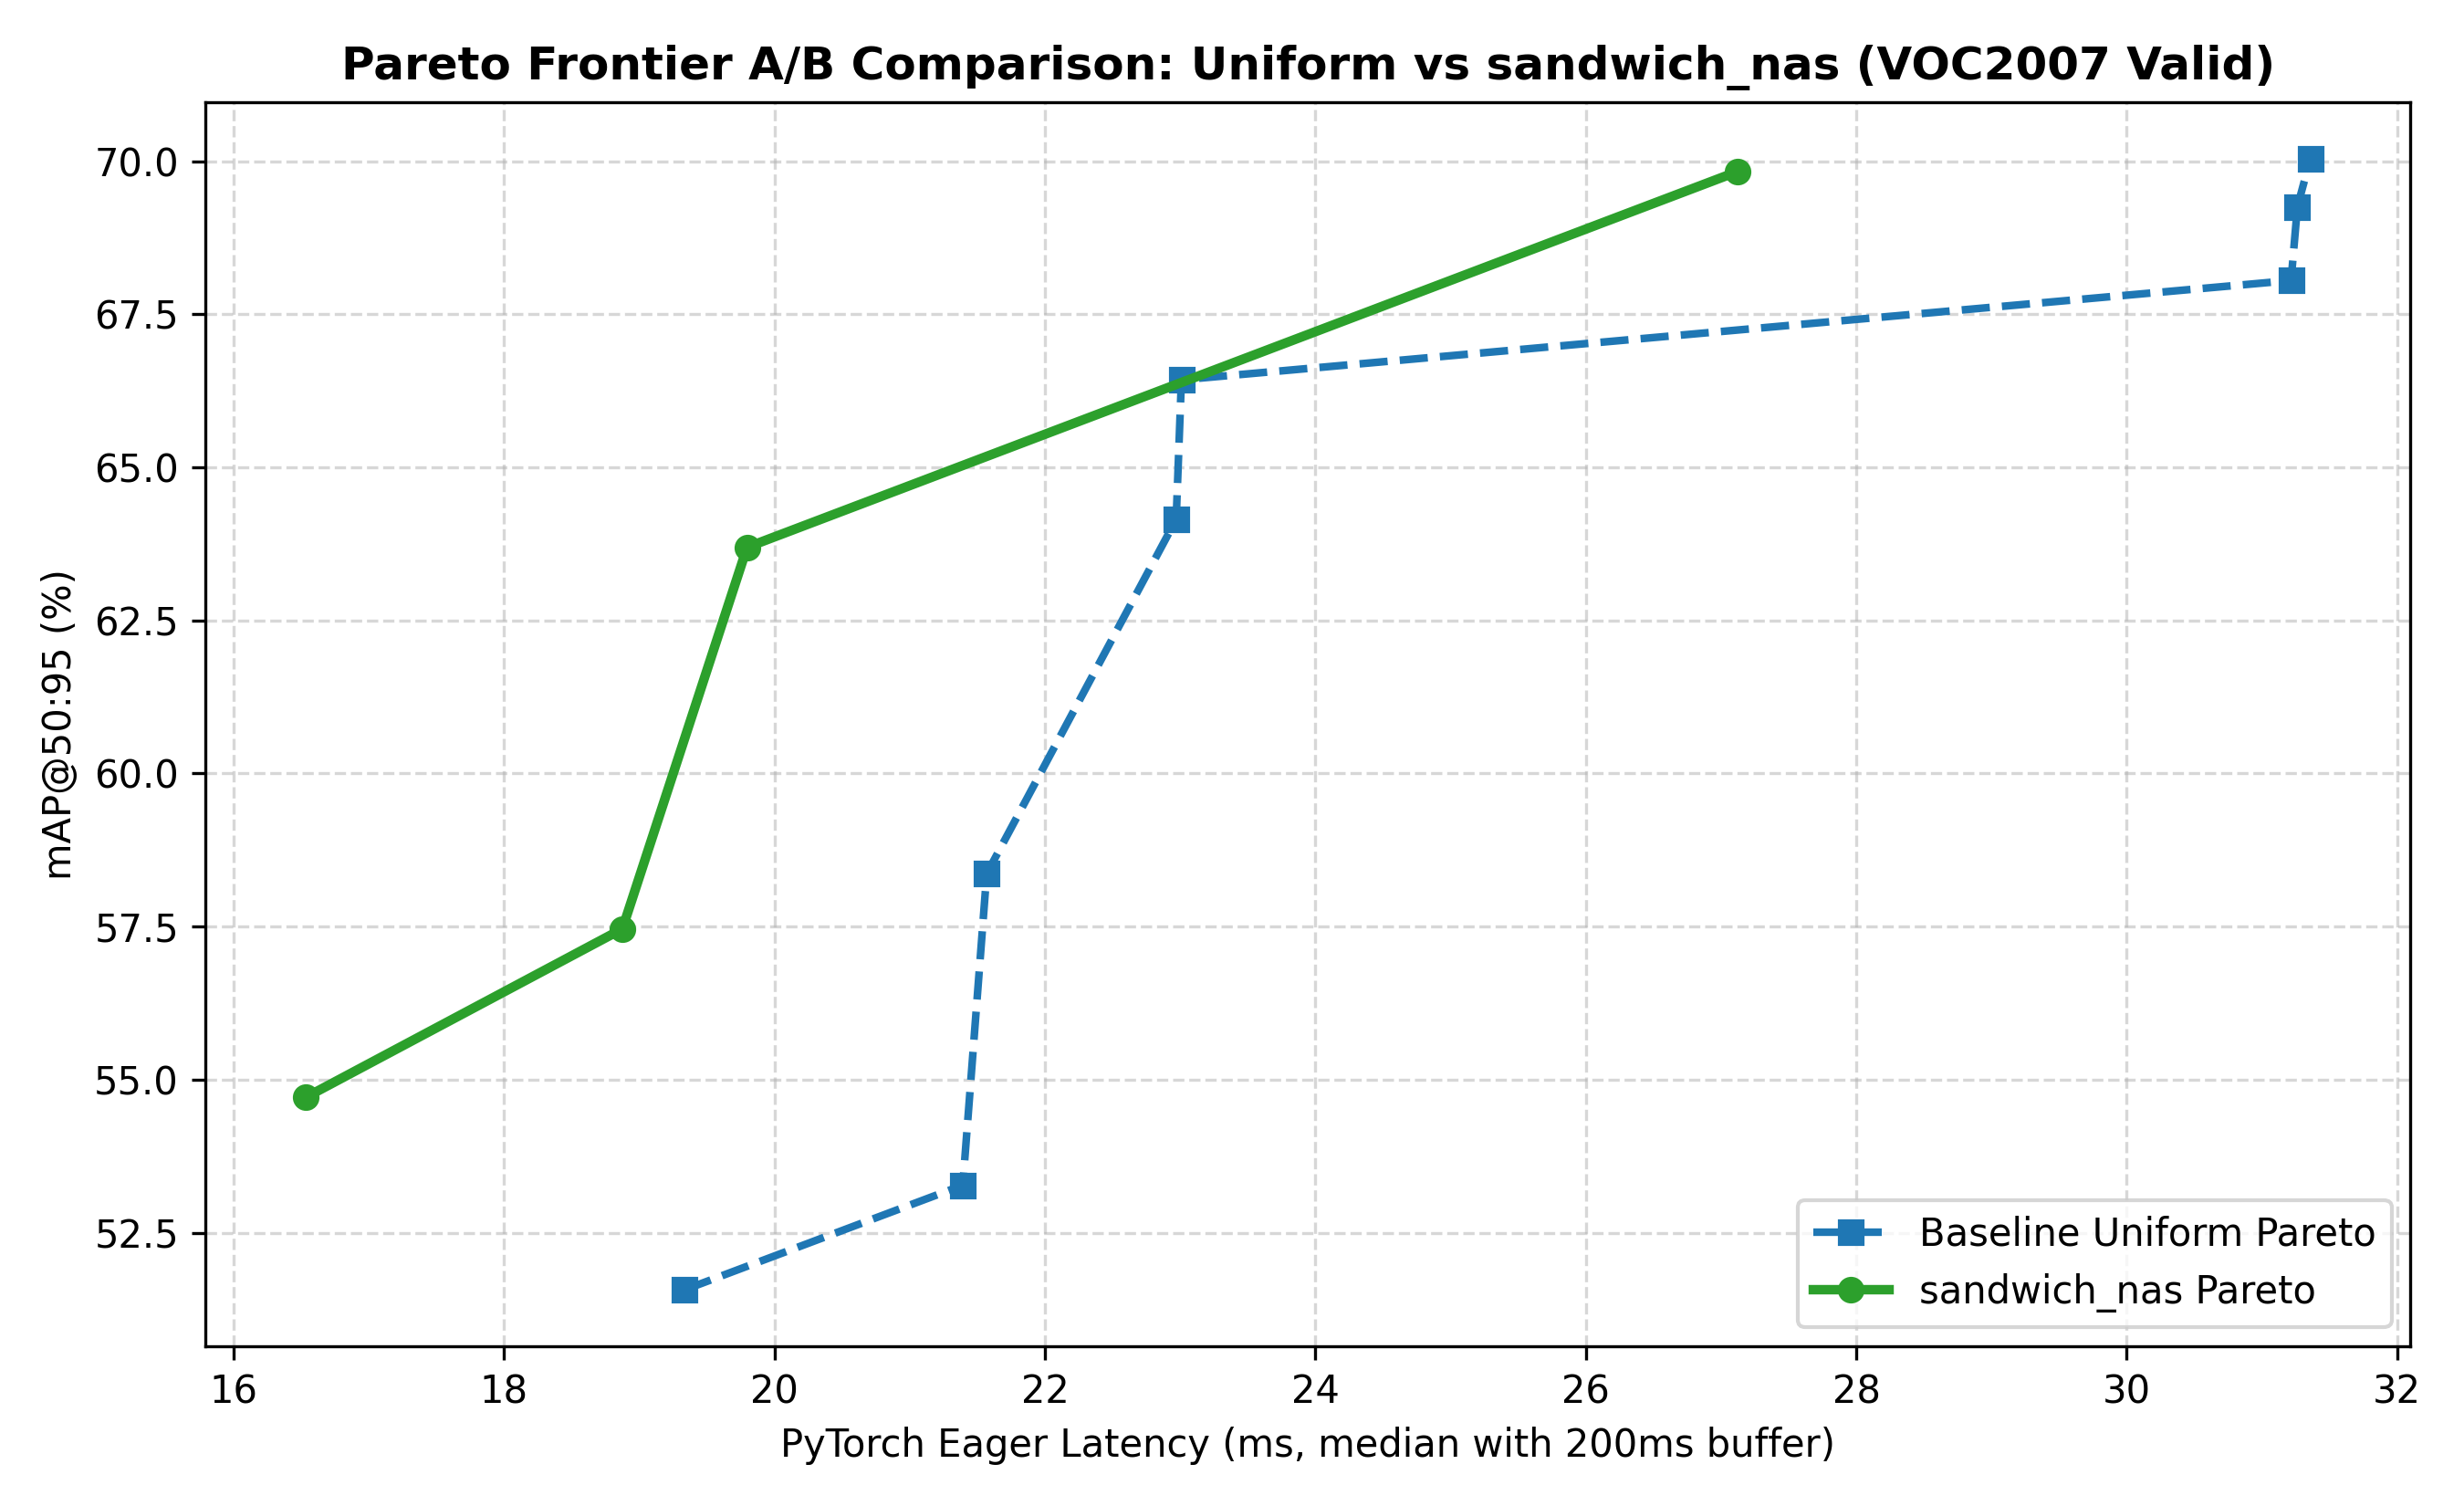

In [20]:
# 7.3. Bảng tổng hợp & Biểu đồ đối chứng A/B: Baseline (Uniform) vs Cải tiến (PAB-NAS / Sandwich)
import matplotlib.pyplot as plt
import pandas as pd

base_val_csv = OUTPUT_DIR / "grid_search" / "nas_validation_results.csv"
base_par_csv = OUTPUT_DIR / "grid_search" / "pareto_frontier.csv"
pab_val_csv = OUTPUT_DIR / "grid_search" / f"nas_validation_results_{PAB_EXP_TAG}.csv"
pab_par_csv = OUTPUT_DIR / "grid_search" / f"pareto_frontier_{PAB_EXP_TAG}.csv"

base_hist_csv = OUTPUT_DIR / "nas" / "nas_train_history.csv"
pab_hist_csv = OUTPUT_DIR / "nas" / f"nas_train_history_{PAB_EXP_TAG}.csv"

if base_val_csv.exists() and pab_val_csv.exists():
    b_val = pd.read_csv(base_val_csv)
    p_val = pd.read_csv(pab_val_csv)
    b_par = pd.read_csv(base_par_csv)
    p_par = pd.read_csv(pab_par_csv)

    # So sánh các mốc kiến trúc trọng tâm: Tiny (320), Nano (384), Peak Pareto (640)
    key_specs = [
        ("Tiny (320/p16/w2/d6/q300)",  (320, 16, 2, 6, 300)),
        ("Nano (384/p16/w2/d6/q300)",  (384, 16, 2, 6, 300)),
        ("Mid  (512/p16/w2/d6/q300)",  (512, 16, 2, 6, 300)),
        ("Peak (640/p16/w2/d6/q300)",  (640, 16, 2, 6, 300)),
    ]

    def _lookup(df, spec):
        r, ps, nw, dl, nq = spec
        sub = df[
            (df["resolution"] == r) & (df["patch_size"] == ps) & (df["num_windows"] == nw)
            & (df["decoder_layers"] == dl) & (df["num_queries"] == nq) & (df["valid"] == True)
        ]
        return sub.iloc[0] if len(sub) else None

    comp_rows = []
    for name, spec in key_specs:
        rb = _lookup(b_val, spec)
        rp = _lookup(p_val, spec)
        if rb is not None and rp is not None:
            comp_rows.append({
                "subnet": name,
                "uniform_mAP(%)": round(rb["map"] * 100, 2),
                f"{PAB_EXP_TAG}_mAP(%)": round(rp["map"] * 100, 2),
                "delta_mAP(%)": round((rp["map"] - rb["map"]) * 100, 2),
                "uniform_mAP50(%)": round(rb["map50"] * 100, 2),
                f"{PAB_EXP_TAG}_mAP50(%)": round(rp["map50"] * 100, 2),
            })

    ab_df = pd.DataFrame(comp_rows)
    ab_csv = OUTPUT_DIR / "grid_search" / f"ab_comparison_uniform_vs_{PAB_EXP_TAG}.csv"
    ab_df.to_csv(ab_csv, index=False)
    print("=== SO SÁNH mAP: BASELINE UNIFORM VS CẢI TIẾN ===")
    display(ab_df)

    if base_hist_csv.exists() and pab_hist_csv.exists():
        bh = pd.read_csv(base_hist_csv)
        ph = pd.read_csv(pab_hist_csv)
        print(
            f"Thời gian train trung bình/epoch: Uniform = {bh['elapsed_sec'].mean()/60:.2f} phút | "
            f"{PAB_EXP_TAG} = {ph['elapsed_sec'].mean()/60:.2f} phút"
        )

    # Vẽ overlay đường biên Pareto Baseline vs Cải tiến
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.plot(b_par["latency_median_ms"], b_par["map"] * 100.0, marker="s", linestyle="--", linewidth=2, color="#1f77b4", label="Baseline Uniform Pareto")
    ax.plot(p_par["latency_median_ms"], p_par["map"] * 100.0, marker="o", linewidth=2.5, color="#2ca02c", label=f"{PAB_EXP_TAG} Pareto")
    ax.set_title(f"Pareto Frontier A/B Comparison: Uniform vs {PAB_EXP_TAG} (VOC2007 Valid)", fontweight="bold")
    ax.set_xlabel("PyTorch Eager Latency (ms, median with 200ms buffer)")
    ax.set_ylabel("mAP@50:95 (%)")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="lower right")
    ab_png = OUTPUT_DIR / "grid_search" / f"ab_pareto_uniform_vs_{PAB_EXP_TAG}.png"
    fig.tight_layout()
    fig.savefig(ab_png, dpi=300)
    plt.close(fig)
    display(Image(filename=str(ab_png)))
else:
    print("Cần có đủ cả kết quả Grid Search của Baseline và bản cải tiến để vẽ bảng đối chứng A/B.")


[Latency Ref] Dùng checkpoint đại diện: /content/drive/MyDrive/RFDETR_Checkpoints/project_checkpoints/nas/nas_supernet_ema_only.pth


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pydantic/main.py:280: PretrainWeightsCompatibilityWarning: RFDETRBaseConfig was instantiated with pretrain_weights=None. The model will be initialised from scratch, which typically produces lower accuracy than fine-tuning from the published checkpoint ('rf-detr-base.pth').
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)


[2026-11-26 12:39:46] [INFO] rfdetr_reproduction.training.checkpoint: Loaded EMA weights from /content/drive/MyDrive/RFDETR_Checkpoints/project_checkpoints/nas/nas_supernet_ema_only.pth (epoch=20)
[2026-11-26 12:39:46] [INFO] rfdetr_reproduction.nas.adapter: [RFDETRNASAdapter] Ready | base_patch=14 | max_dec_layers=6 | max_queries=300 | window_holders=16
[Latency Ref] Đang đo 37 cấu hình (warmup=15, repeats=40, buffer=0.2s)...
  -> 10/37 configs | last=384/p16/d1: 19.08 ms
  -> 20/37 configs | last=384/p16/d2: 20.99 ms
  -> 30/37 configs | last=512/p16/d2: 20.93 ms
  -> 37/37 configs | last=640/p16/d6: 28.23 ms
[Latency Ref] Đã lưu bảng chuẩn -> /content/drive/MyDrive/RFDETR_Checkpoints/results_cocoinit/grid_search/latency_ref.csv (37 cấu hình)
[Uniform     ] Valid=37 | Pareto points=9 | Max mAP=70.04%
[pab_nas     ] Valid=37 | Pareto points=7 | Max mAP=71.02%
[sandwich_nas] Valid=37 | Pareto points=7 | Max mAP=69.83%


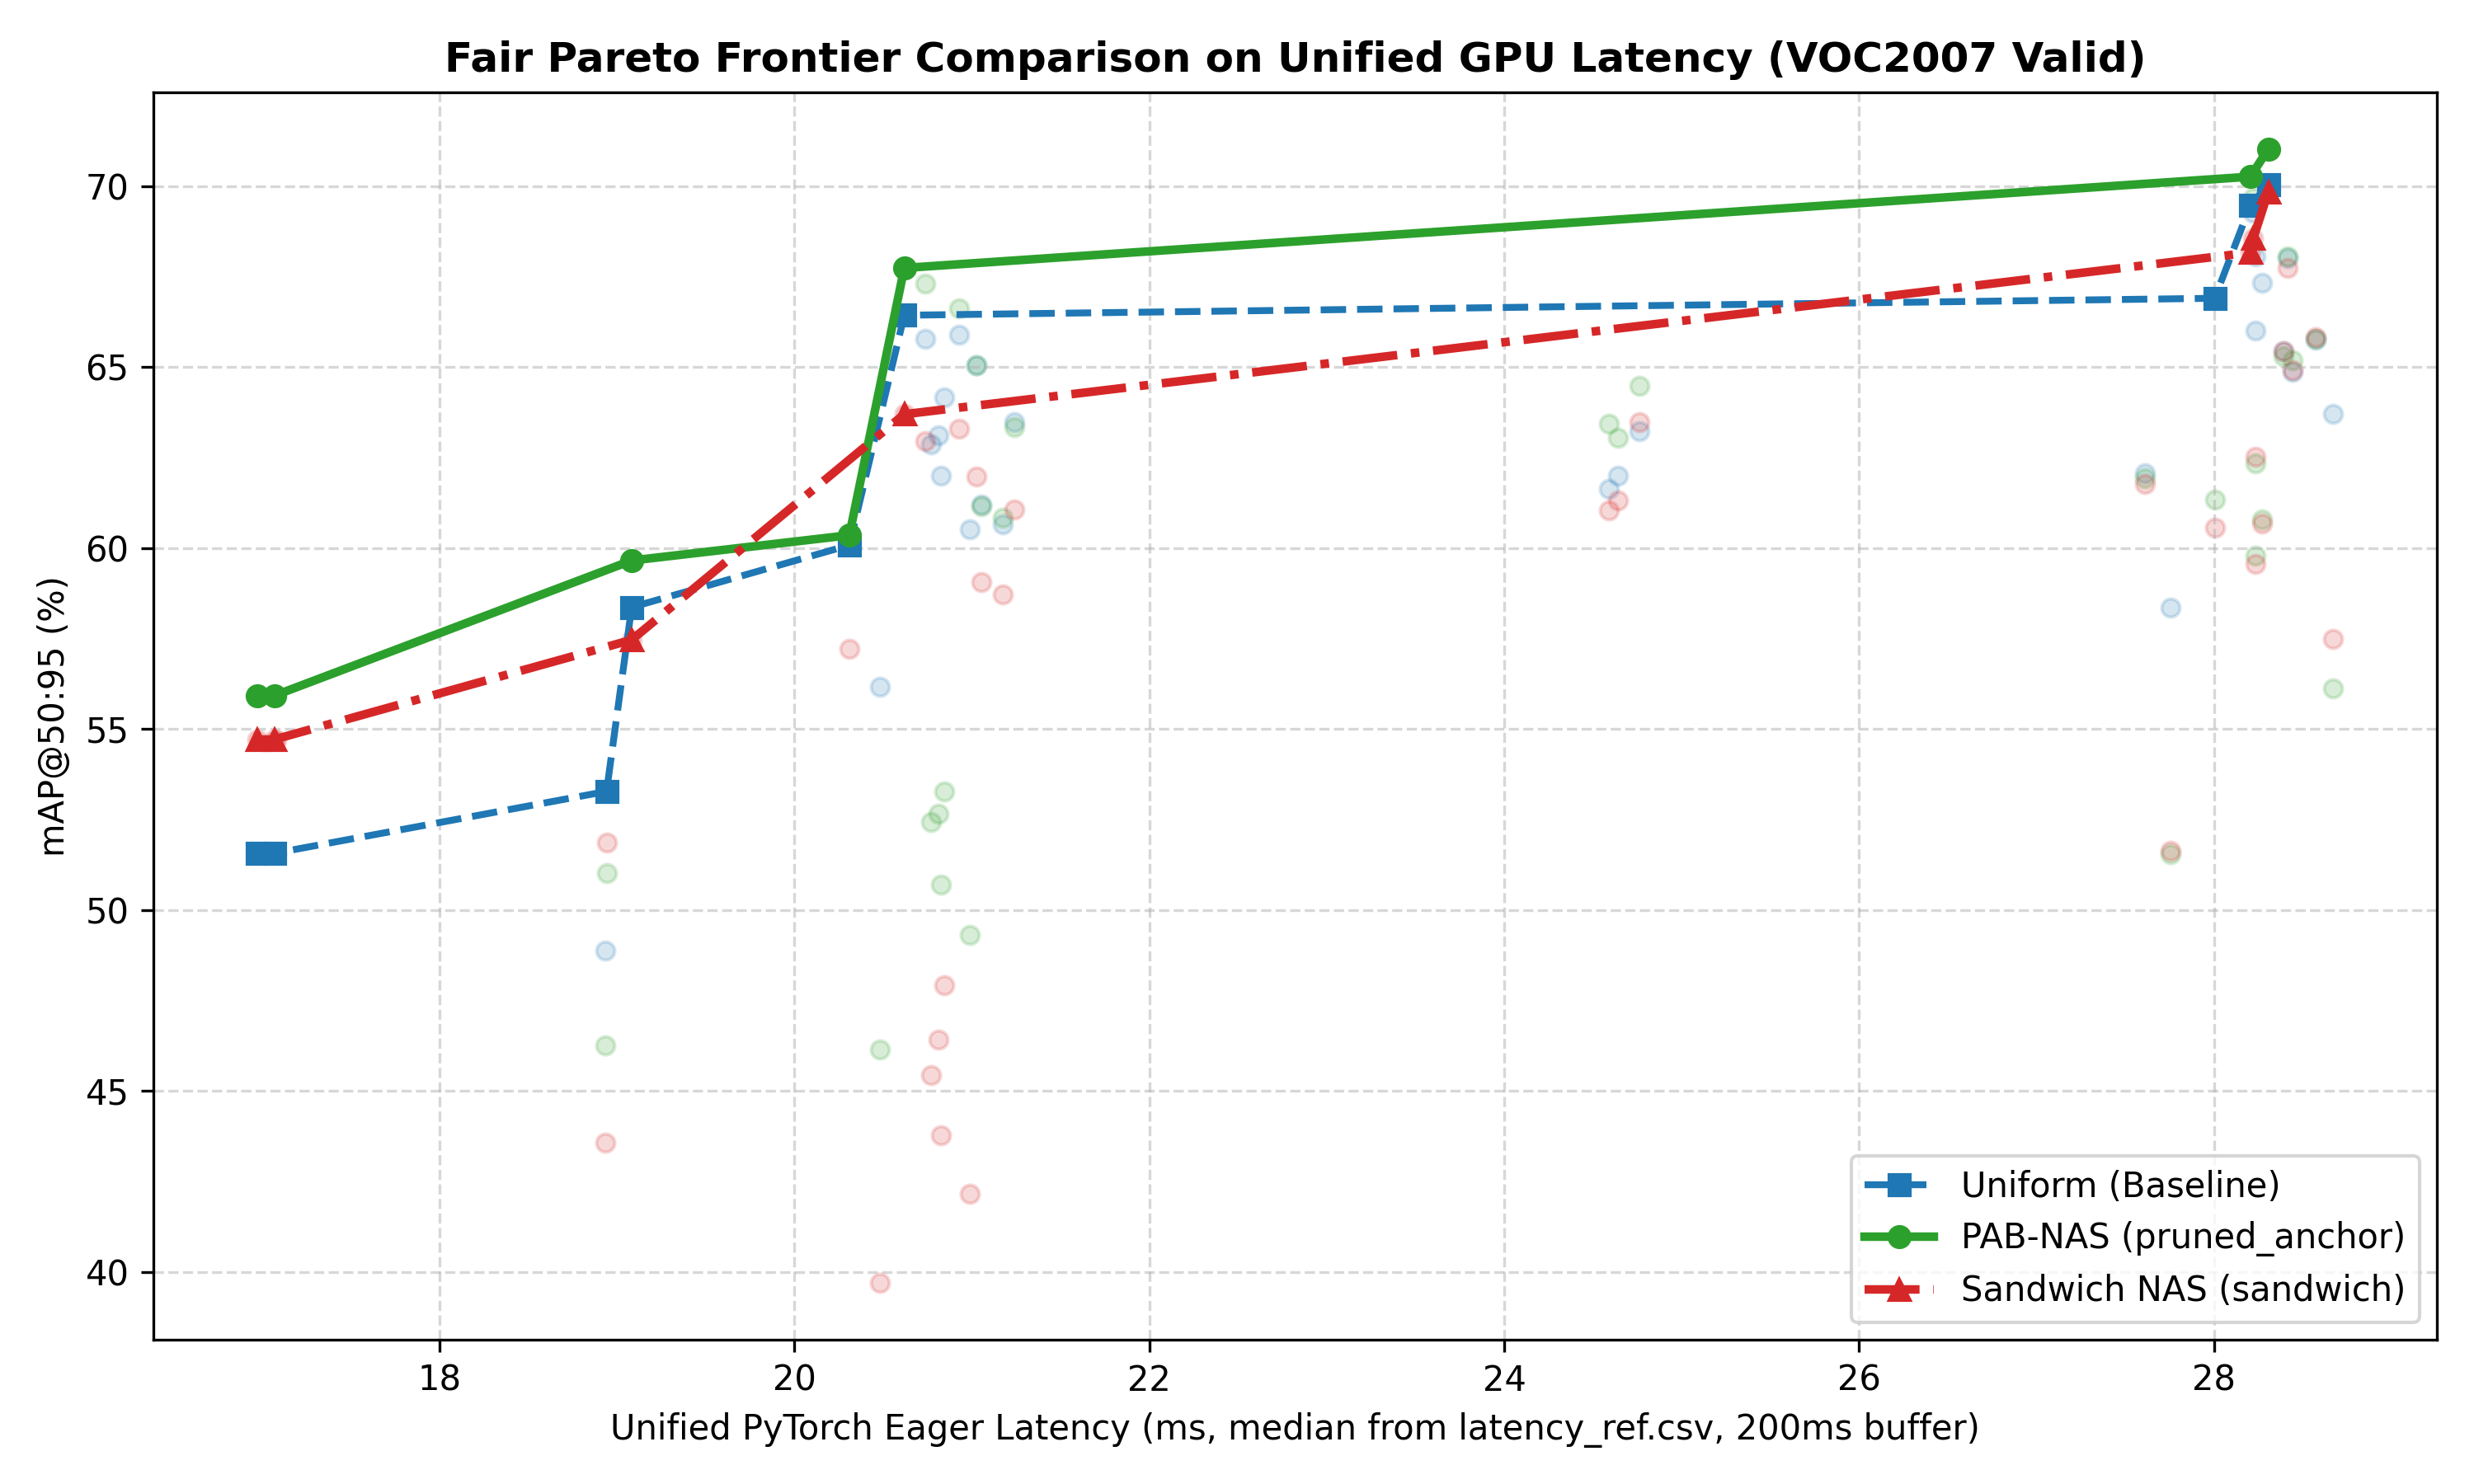


=== BẢNG SO SÁNH 3 PHƯƠNG PHÁP TRÊN CÙNG LATENCY CHUẨN ===


,subnet,latency_ms,Uniform_mAP(%),pab_nas_mAP(%),sandwich_nas_mAP(%)
0,Tiny (320/p16/w2/d6/q300),27.61,62.06,61.93,61.76
1,Nano (384/p16/w2/d6/q300),28.57,65.75,65.79,65.82
2,Mid (512/p16/w2/d6/q300),28.22,69.26,69.67,68.56
3,Peak (640/p16/w2/d6/q300),28.31,70.04,71.02,69.83


In [23]:
# 7.4. Đo Latency chuẩn 1 lần (latency_ref.csv) & Vẽ Pareto 3 đường công bằng (Uniform vs pab_nas vs sandwich_nas)
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

from configs.paper_config import NUM_CLASSES, PAPER
from rfdetr_reproduction.nas.adapter import RFDETRNASAdapter, build_official_rfdetr_supernet
from rfdetr_reproduction.nas.search_space import build_representative_infer_configs
from rfdetr_reproduction.search.evaluation import benchmark_subnet_latency
from rfdetr_reproduction.search.pareto import pareto_frontier
from rfdetr_reproduction.training.checkpoint import load_ema_weights
from rfdetr_reproduction.training.train_utils import resolve_device_and_amp

RUN_FAIR_3WAY_PARETO = True
FORCE_REBENCH_LATENCY = False  # Đổi thành True nếu muốn đo lại latency_ref.csv từ đầu
LAT_WARMUP = 15
LAT_REPEATS = 40
LAT_BUFFER_SEC = 0.2

CFG_KEYS = ["resolution", "patch_size", "num_windows", "decoder_layers", "num_queries"]
LATENCY_REF_CSV = OUTPUT_DIR / "grid_search" / "latency_ref.csv"

METHOD_CSVS = {
    "Uniform":      OUTPUT_DIR / "grid_search" / "nas_validation_results.csv",
    "pab_nas":      OUTPUT_DIR / "grid_search" / "nas_validation_results_pab_nas.csv",
    "sandwich_nas": OUTPUT_DIR / "grid_search" / "nas_validation_results_sandwich_nas.csv",
}

if RUN_FAIR_3WAY_PARETO:
    # 1. Tạo hoặc nạp bảng latency_ref.csv (đo 1 lần duy nhất trong cùng 1 phiên GPU)
    if FORCE_REBENCH_LATENCY or not LATENCY_REF_CSV.exists():
        # Chọn 1 checkpoint bất kỳ (cả 3 phương pháp dùng chung kiến trúc LWDETR + DINOv2-S)
        ckpt_candidates = [
            CKPT_DIR / "nas" / "nas_supernet_ema_only.pth",
            CKPT_DIR / "nas" / "nas_supernet_pab_nas_ema_only.pth",
            CKPT_DIR / "nas" / "nas_supernet_sandwich_nas_ema_only.pth",
            CKPT_DIR / "nas" / "nas_supernet_latest.pth",
            DRIVE_FULL_CKPT,
        ]
        ref_ckpt = next((p for p in ckpt_candidates if p.exists()), None)
        assert ref_ckpt is not None, "Không tìm thấy checkpoint nào để đo latency chuẩn!"
        print(f"[Latency Ref] Dùng checkpoint đại diện: {ref_ckpt}")

        # Lấy hợp tất cả cấu hình xuất hiện trong các bảng Grid Search (hoặc 37 cấu hình representative)
        cfg_frames = []
        for csv_p in METHOD_CSVS.values():
            if csv_p.exists():
                df_tmp = pd.read_csv(csv_p)
                cfg_frames.append(df_tmp[CFG_KEYS].drop_duplicates())
        if cfg_frames:
            unique_cfgs_df = pd.concat(cfg_frames, ignore_index=True).drop_duplicates().reset_index(drop=True)
            cfgs_to_bench = unique_cfgs_df.to_dict("records")
        else:
            cfgs_to_bench = build_representative_infer_configs(paper_config=PAPER)

        device, amp_dtype, is_cuda = resolve_device_and_amp("cuda")
        official_model, _, _, _ = build_official_rfdetr_supernet(
            dataset_root=DATA_DIR / "voc2007_rfdetr",
            num_classes=NUM_CLASSES,
            device=device,
            paper_config=PAPER,
        )
        load_ema_weights(ref_ckpt, official_model, device=device)
        adapter = RFDETRNASAdapter(official_model, paper_config=PAPER).to(device).eval()

        print(f"[Latency Ref] Đang đo {len(cfgs_to_bench)} cấu hình (warmup={LAT_WARMUP}, repeats={LAT_REPEATS}, buffer={LAT_BUFFER_SEC}s)...")
        lat_rows = []
        for idx, cfg in enumerate(cfgs_to_bench, 1):
            cfg_int = {k: int(cfg[k]) for k in CFG_KEYS}
            stats = benchmark_subnet_latency(
                adapter,
                cfg_int,
                device=device,
                amp_dtype=amp_dtype,
                warmup=LAT_WARMUP,
                repeats=LAT_REPEATS,
                buffer_sec=LAT_BUFFER_SEC,
            )
            lat_rows.append({**cfg_int, **stats})
            if idx % 10 == 0 or idx == len(cfgs_to_bench):
                print(f"  -> {idx}/{len(cfgs_to_bench)} configs | last={cfg_int['resolution']}/p{cfg_int['patch_size']}/d{cfg_int['decoder_layers']}: {stats['latency_median_ms']:.2f} ms")

        lat_ref_df = pd.DataFrame(lat_rows)
        lat_ref_df.to_csv(LATENCY_REF_CSV, index=False)
        del adapter, official_model
        if is_cuda:
            torch.cuda.empty_cache()
        print(f"[Latency Ref] Đã lưu bảng chuẩn -> {LATENCY_REF_CSV} ({len(lat_ref_df)} cấu hình)")
    else:
        lat_ref_df = pd.read_csv(LATENCY_REF_CSV)
        print(f"[Latency Ref] Dùng lại bảng chuẩn đã có -> {LATENCY_REF_CSV} ({len(lat_ref_df)} cấu hình)")

    # 2. Ghép cột latency_ms chuẩn vào kết quả mAP của cả 3 phương pháp & tính lại Pareto
    merged_by_method = {}
    frontiers_by_method = {}
    lat_cols = ["latency_median_ms", "latency_mean_ms", "latency_p90_ms", "latency_std_ms", "peak_vram_gb"]

    for method_name, csv_path in METHOD_CSVS.items():
        if not csv_path.exists():
            print(f"[WARN] Bỏ qua {method_name} vì chưa có file: {csv_path}")
            continue
        df_m = pd.read_csv(csv_path)
        for k in CFG_KEYS:
            df_m[k] = df_m[k].astype(int)
        # Xóa cột latency đo ở phiên cũ và ghép latency_ref.csv chuẩn
        df_clean = df_m.drop(columns=[c for c in lat_cols if c in df_m.columns], errors="ignore")
        df_merged = df_clean.merge(lat_ref_df[CFG_KEYS + lat_cols], on=CFG_KEYS, how="left")
        df_merged["latency_ms"] = df_merged["latency_median_ms"]

        out_merged = OUTPUT_DIR / "grid_search" / f"nas_validation_results_{method_name.lower()}_fair_lat.csv"
        df_merged.to_csv(out_merged, index=False)

        f_df = pareto_frontier(df_merged, accuracy_col="map", latency_col="latency_ms")
        f_df.to_csv(OUTPUT_DIR / "grid_search" / f"pareto_frontier_{method_name.lower()}_fair_lat.csv", index=False)

        merged_by_method[method_name] = df_merged
        frontiers_by_method[method_name] = f_df
        print(f"[{method_name:12s}] Valid={int((df_merged['valid'] == True).sum())} | Pareto points={len(f_df)} | Max mAP={f_df['map'].max()*100:.2f}%")

    # 3. Vẽ chung 1 biểu đồ Pareto 3 đường (Uniform vs pab_nas vs sandwich_nas) trên cùng trục Latency chuẩn
    if frontiers_by_method:
        styles = {
            "Uniform":      {"color": "#1f77b4", "marker": "s", "linestyle": "--", "linewidth": 2.0, "label": "Uniform (Baseline)"},
            "pab_nas":      {"color": "#2ca02c", "marker": "o", "linestyle": "-",  "linewidth": 2.5, "label": "PAB-NAS (pruned_anchor)"},
            "sandwich_nas": {"color": "#d62728", "marker": "^", "linestyle": "-.", "linewidth": 2.5, "label": "Sandwich NAS (sandwich)"},
        }

        fig, ax = plt.subplots(figsize=(10, 6))
        for m_name, df_m in merged_by_method.items():
            v_df = df_m[df_m["valid"] == True]
            st = styles[m_name]
            ax.scatter(v_df["latency_ms"], v_df["map"] * 100.0, alpha=0.18, s=28, color=st["color"])
            f_df = frontiers_by_method[m_name]
            ax.plot(
                f_df["latency_ms"],
                f_df["map"] * 100.0,
                color=st["color"],
                marker=st["marker"],
                linestyle=st["linestyle"],
                linewidth=st["linewidth"],
                markersize=6,
                label=st["label"],
            )

        ax.set_title(
            "Fair Pareto Frontier Comparison on Unified GPU Latency (VOC2007 Valid)",
            fontweight="bold",
        )
        ax.set_xlabel("Unified PyTorch Eager Latency (ms, median from latency_ref.csv, 200ms buffer)")
        ax.set_ylabel("mAP@50:95 (%)")
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend(loc="lower right", fontsize=10)
        fair_png = OUTPUT_DIR / "grid_search" / "pareto_3way_fair_latency.png"
        fig.tight_layout()
        fig.savefig(fair_png, dpi=300)
        plt.close(fig)
        display(Image(filename=str(fair_png)))

        # 4. Bảng đối chiếu 3 phương pháp tại các mốc kiến trúc trọng tâm (cùng 1 cột latency_ms)
        key_specs = [
            ("Tiny (320/p16/w2/d6/q300)", (320, 16, 2, 6, 300)),
            ("Nano (384/p16/w2/d6/q300)", (384, 16, 2, 6, 300)),
            ("Mid  (512/p16/w2/d6/q300)", (512, 16, 2, 6, 300)),
            ("Peak (640/p16/w2/d6/q300)", (640, 16, 2, 6, 300)),
        ]
        summary_rows = []
        for label, (r, ps, nw, dl, nq) in key_specs:
            row_out = {"subnet": label}
            ref_match = lat_ref_df[
                (lat_ref_df["resolution"] == r) & (lat_ref_df["patch_size"] == ps)
                & (lat_ref_df["num_windows"] == nw) & (lat_ref_df["decoder_layers"] == dl)
                & (lat_ref_df["num_queries"] == nq)
            ]
            row_out["latency_ms"] = round(float(ref_match.iloc[0]["latency_median_ms"]), 2) if len(ref_match) else None
            for m_name, df_m in merged_by_method.items():
                sub = df_m[
                    (df_m["resolution"] == r) & (df_m["patch_size"] == ps)
                    & (df_m["num_windows"] == nw) & (df_m["decoder_layers"] == dl)
                    & (df_m["num_queries"] == nq) & (df_m["valid"] == True)
                ]
                row_out[f"{m_name}_mAP(%)"] = round(float(sub.iloc[0]["map"]) * 100.0, 2) if len(sub) else None
            summary_rows.append(row_out)

        fair_summary_df = pd.DataFrame(summary_rows)
        fair_summary_csv = OUTPUT_DIR / "grid_search" / "ab_3way_summary_fair_latency.csv"
        fair_summary_df.to_csv(fair_summary_csv, index=False)
        print("\n=== BẢNG SO SÁNH 3 PHƯƠNG PHÁP TRÊN CÙNG LATENCY CHUẨN ===")
        display(fair_summary_df)


loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
[VOC2007 Test] Đã nạp 4952 ảnh test độc lập.


/usr/local/lib/python3.13/dist-packages/pydantic/main.py:280: PretrainWeightsCompatibilityWarning: RFDETRBaseConfig was instantiated with pretrain_weights=None. The model will be initialised from scratch, which typically produces lower accuracy than fine-tuning from the published checkpoint ('rf-detr-base.pth').
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)


[2026-11-26 14:00:38] [INFO] rfdetr_reproduction.nas.adapter: [RFDETRNASAdapter] Ready | base_patch=14 | max_dec_layers=6 | max_queries=300 | window_holders=16
[INFO] FlopCounterMode không hỗ trợ 1 op (AssertionError), chuyển sang bộ đếm hook Conv2d/Linear...
[GFLOPs] Tiny (320/p16/w2/d6/q300)    -> 25.13 GFLOPs (Params=32.95M)
[INFO] FlopCounterMode không hỗ trợ 1 op (AssertionError), chuyển sang bộ đếm hook Conv2d/Linear...
[GFLOPs] Nano (384/p16/w2/d6/q300)    -> 34.94 GFLOPs (Params=32.95M)
[INFO] FlopCounterMode không hỗ trợ 1 op (AssertionError), chuyển sang bộ đếm hook Conv2d/Linear...
[GFLOPs] Mid  (512/p16/w2/d6/q300)    -> 62.48 GFLOPs (Params=32.95M)
[INFO] FlopCounterMode không hỗ trợ 1 op (AssertionError), chuyển sang bộ đếm hook Conv2d/Linear...
[GFLOPs] Peak (640/p16/w2/d6/q300)    -> 103.33 GFLOPs (Params=32.95M)
[Resume] Đã cập nhật bổ sung cột gflops vào voc2007_test_3way_eval.csv (không cần chấm lại mAP Test).
[2026-11-26 14:00:39] [INFO] rfdetr_reproduction.training

,method,subnet,gflops,latency_ms,test_map,test_map50,test_ap_s,test_ap_m,test_ap_l
0,Uniform,Tiny (320/p16/w2/d6/q300),25.13,27.61,61.65,82.08,16.37,38.25,70.31
1,Uniform,Nano (384/p16/w2/d6/q300),34.94,28.57,64.91,84.94,21.60,44.36,72.87
2,Uniform,Mid (512/p16/w2/d6/q300),62.48,28.22,67.94,86.84,29.81,51.25,74.62
3,Uniform,Peak (640/p16/w2/d6/q300),103.33,28.31,68.25,86.89,29.84,52.80,74.51
4,pab_nas,Tiny (320/p16/w2/d6/q300),25.13,27.61,62.90,82.98,14.34,38.25,72.12
5,pab_nas,Nano (384/p16/w2/d6/q300),34.94,28.57,66.61,86.02,18.55,44.83,74.77
6,pab_nas,Mid (512/p16/w2/d6/q300),62.48,28.22,70.08,88.34,26.25,52.27,76.98
7,pab_nas,Peak (640/p16/w2/d6/q300),103.33,28.31,71.17,88.91,31.04,54.88,77.44
8,sandwich_nas,Tiny (320/p16/w2/d6/q300),25.13,27.61,62.27,82.32,14.03,38.00,71.47
9,sandwich_nas,Nano (384/p16/w2/d6/q300),34.94,28.57,66.45,86.02,21.06,44.50,74.78



=== BẢNG TỔNG HỢP CUỐI CÙNG TRÊN VOC2007 TEST -> final_report_table_voc2007_test.csv ===


,model,resolution,gflops,latency_ms,test_map(%),test_map50(%)
0,YOLOv8n,384,NaN,12.48,53.87,75.10
1,YOLO11n,384,NaN,14.99,53.29,74.59
2,RF-DETR-Uniform (Tiny),320,25.13,27.61,61.65,82.08
3,RF-DETR-Uniform (Nano),384,34.94,28.57,64.91,84.94
4,RF-DETR-Uniform (Mid),512,62.48,28.22,67.94,86.84
5,RF-DETR-Uniform (Peak),640,103.33,28.31,68.25,86.89
6,RF-DETR-pab_nas (Tiny),320,25.13,27.61,62.90,82.98
7,RF-DETR-pab_nas (Nano),384,34.94,28.57,66.61,86.02
8,RF-DETR-pab_nas (Mid),512,62.48,28.22,70.08,88.34
9,RF-DETR-pab_nas (Peak),640,103.33,28.31,71.17,88.91


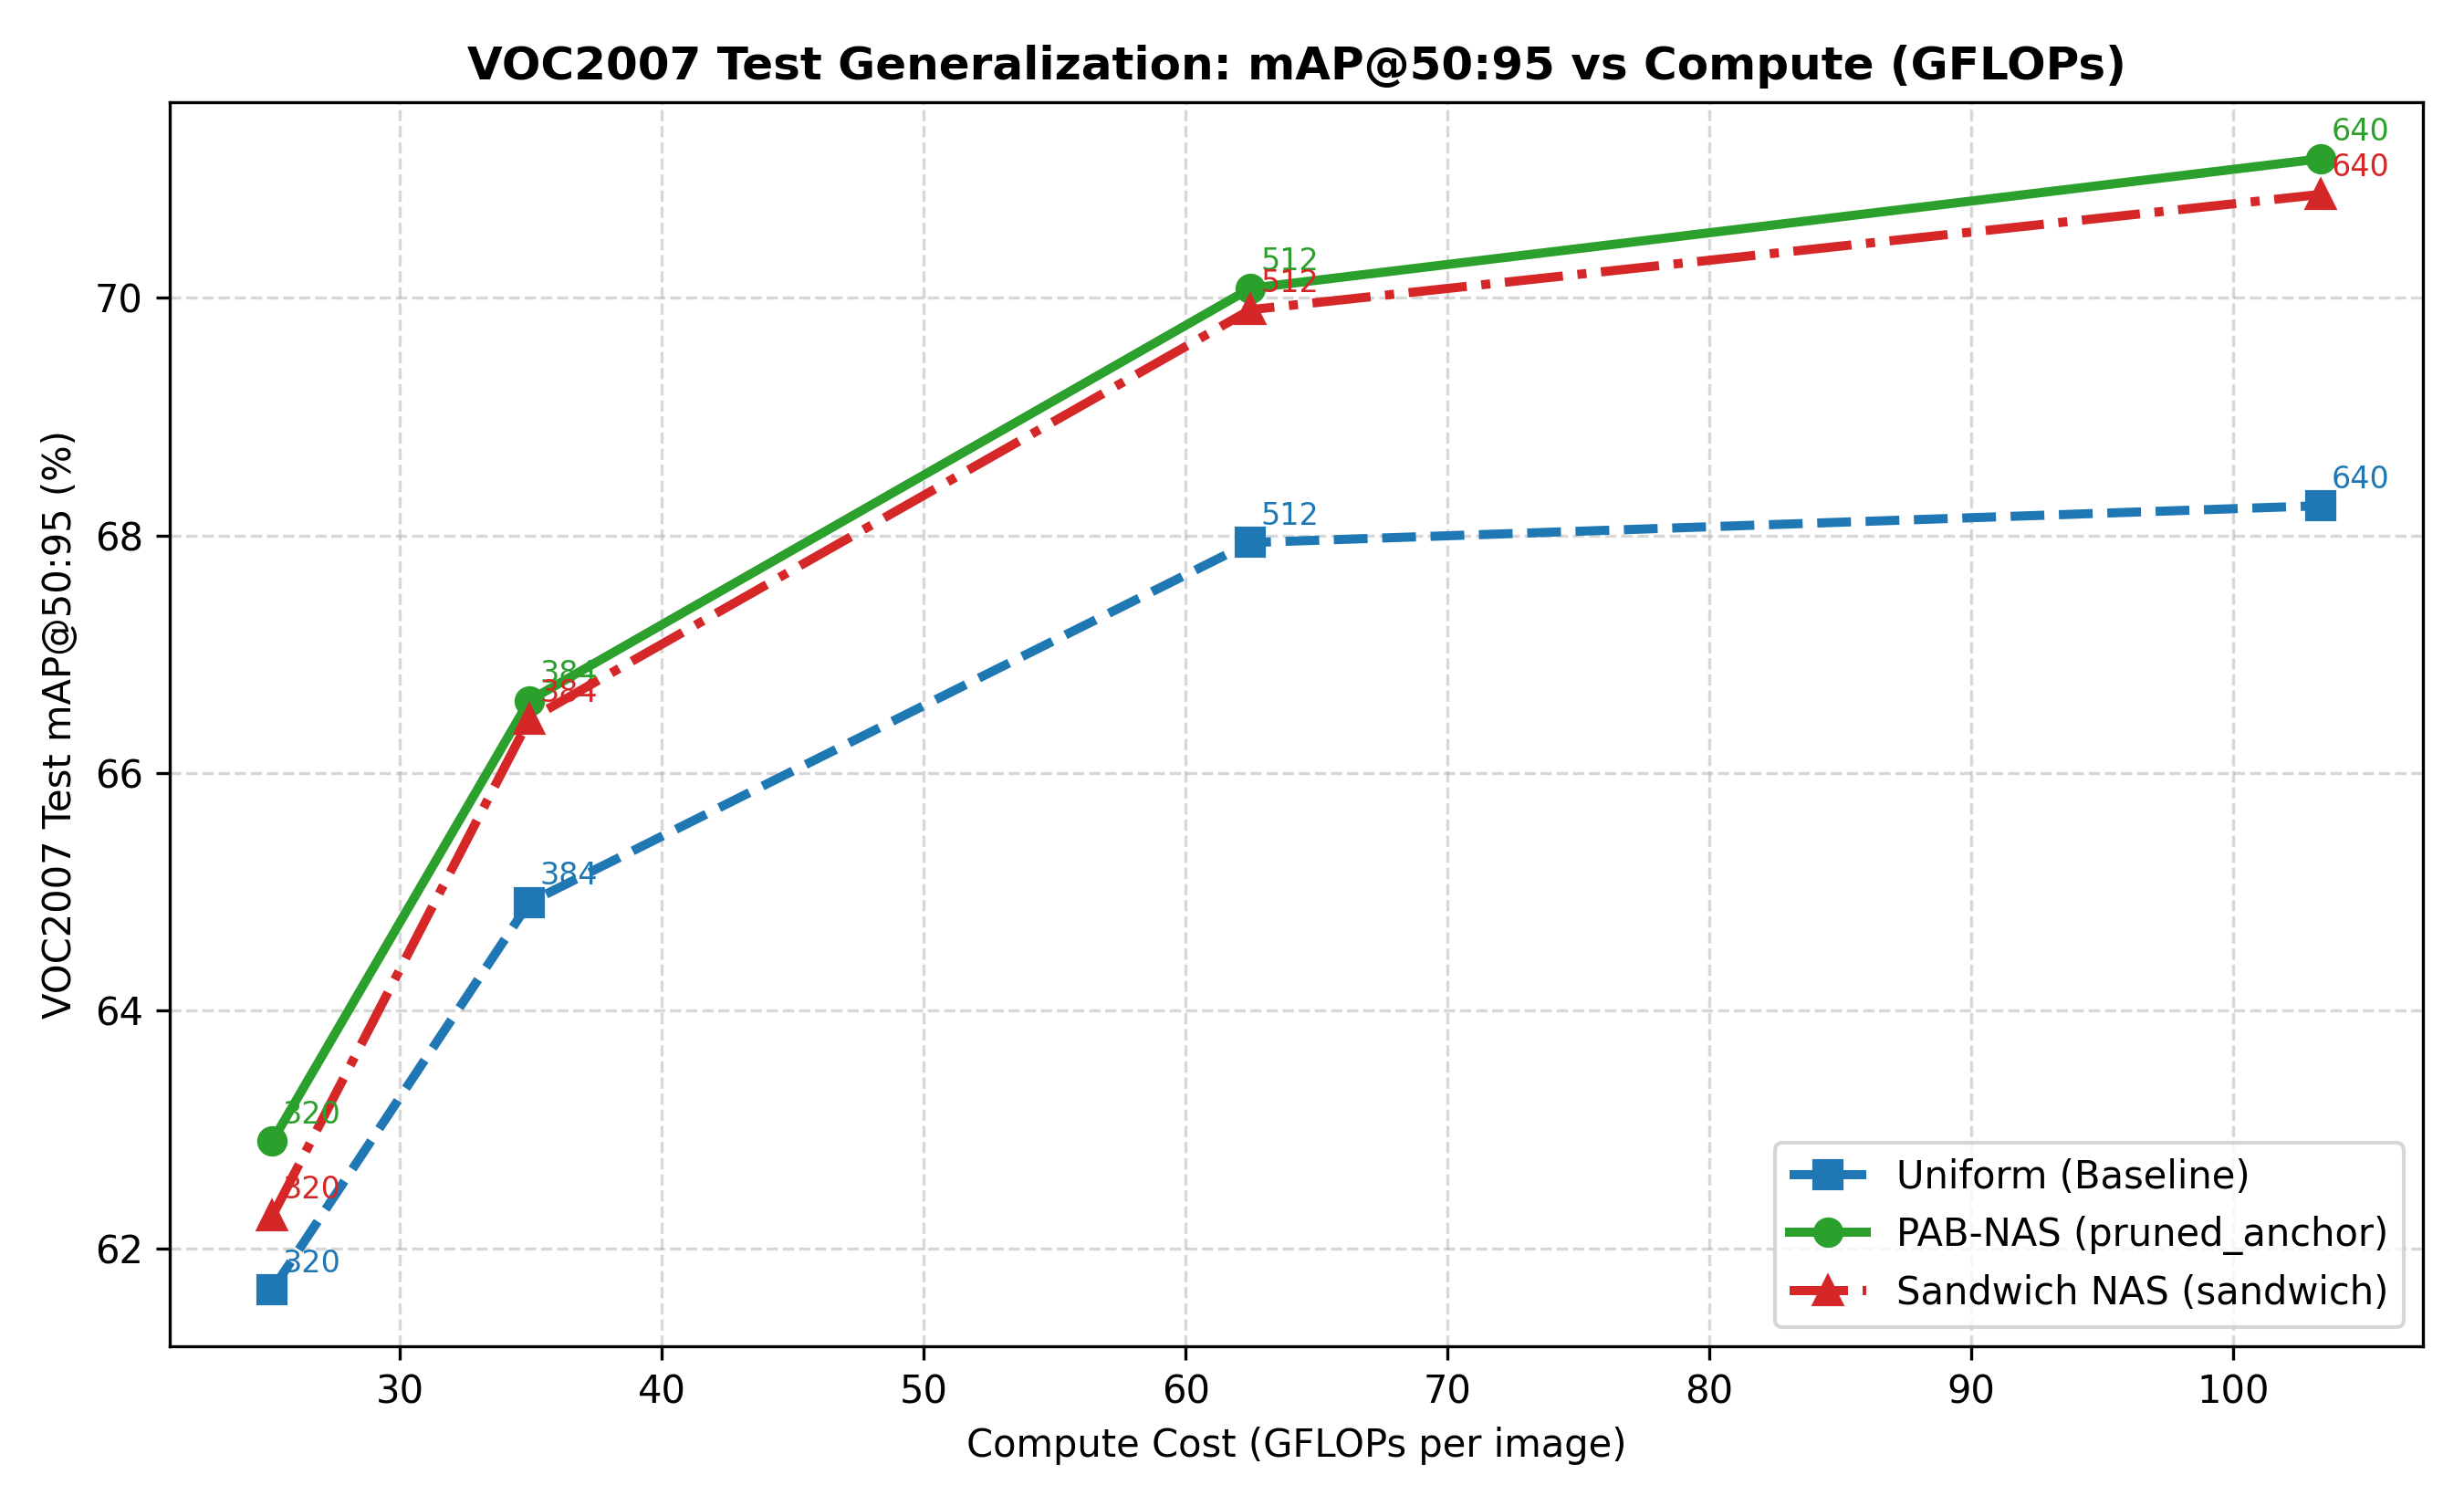

In [25]:
# 7.5. Chấm độc lập trên VOC2007 TEST + Đo GFLOPs (PyTorch FlopCounterMode) + Bảng tổng hợp cuối (kèm YOLOv8n / YOLO11n)
import importlib
import site
import sys
from pathlib import Path

site.main()
importlib.invalidate_caches()
_src_dir = str((Path.cwd() / "src").resolve())
if Path(_src_dir).is_dir() and _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display

from configs.paper_config import NUM_CLASSES, PAPER
from rfdetr_reproduction.data.dataset import SymmetricVOCDetectionDataset
from rfdetr_reproduction.nas.adapter import RFDETRNASAdapter, build_official_rfdetr_supernet
from rfdetr_reproduction.search.evaluation import evaluate_subnet_coco
from rfdetr_reproduction.training.checkpoint import load_ema_weights
from rfdetr_reproduction.training.train_utils import resolve_device_and_amp

RUN_TEST_FINAL_EVAL = True
# "key_4" (Tiny 320, Nano 384, Mid 512, Peak 640 — nhanh ~5 phút) | "pareto_union" (toàn bộ điểm Pareto của 3 bản)
TEST_EVAL_SCOPE = "key_4"

CFG_KEYS = ["resolution", "patch_size", "num_windows", "decoder_layers", "num_queries"]
TEST_EVAL_CSV = OUTPUT_DIR / "grid_search" / "voc2007_test_3way_eval.csv"
FINAL_TABLE_CSV = OUTPUT_DIR / "grid_search" / "final_report_table_voc2007_test.csv"
LATENCY_REF_CSV = OUTPUT_DIR / "grid_search" / "latency_ref.csv"

KEY_4_SPECS = [
    ("Tiny (320/p16/w2/d6/q300)", {"resolution": 320, "patch_size": 16, "num_windows": 2, "decoder_layers": 6, "num_queries": 300}),
    ("Nano (384/p16/w2/d6/q300)", {"resolution": 384, "patch_size": 16, "num_windows": 2, "decoder_layers": 6, "num_queries": 300}),
    ("Mid  (512/p16/w2/d6/q300)", {"resolution": 512, "patch_size": 16, "num_windows": 2, "decoder_layers": 6, "num_queries": 300}),
    ("Peak (640/p16/w2/d6/q300)", {"resolution": 640, "patch_size": 16, "num_windows": 2, "decoder_layers": 6, "num_queries": 300}),
]

METHOD_CKPTS = {
    "Uniform":      CKPT_DIR / "nas" / "nas_supernet_ema_only.pth",
    "pab_nas":      CKPT_DIR / "nas" / "nas_supernet_pab_nas_ema_only.pth",
    "sandwich_nas": CKPT_DIR / "nas" / "nas_supernet_sandwich_nas_ema_only.pth",
}


def _measure_gflops(adapter: RFDETRNASAdapter, cfg: dict, device: torch.device) -> float:
    """Đo GFLOPs thực tế cho 1 subnet (warm-up _PI_CACHE trước, ưu tiên FlopCounterMode, dự phòng hook Conv2d/Linear)."""
    adapter.eval()
    adapter.activate_subnet(cfg, mode="inference")
    res = int(cfg["resolution"])
    x = torch.randn(1, 3, res, res, device=device)

    # Warm-up 1 lần ngoài FlopCounterMode để _PI_CACHE tính sẵn torch.linalg.pinv
    with torch.no_grad():
        _ = adapter(x)

    # Cách 1: PyTorch FlopCounterMode
    try:
        from torch.utils.flop_counter import FlopCounterMode

        with torch.no_grad(), FlopCounterMode(display=False) as fcm:
            _ = adapter(x)
        total_flops = float(fcm.get_total_flops())
        if total_flops > 0:
            return round(total_flops / 1e9, 2)
    except Exception as exc:
        print(f"[INFO] FlopCounterMode không hỗ trợ 1 op ({type(exc).__name__}), chuyển sang bộ đếm hook Conv2d/Linear...")

    # Cách 2 (Dự phòng luôn hoạt động): forward hooks đếm MACs*2 trên Conv2d & Linear + Self-Attention
    flops_acc = [0.0]
    hooks = []

    def _conv_hook(mod, inp, out):
        if isinstance(out, torch.Tensor) and out.ndim == 4:
            _, c_out, h_out, w_out = out.shape
            k_h, k_w = mod.kernel_size if isinstance(mod.kernel_size, tuple) else (mod.kernel_size, mod.kernel_size)
            c_in_per_g = mod.in_channels // mod.groups
            flops_acc[0] += 2.0 * h_out * w_out * c_out * c_in_per_g * k_h * k_w

    def _linear_hook(mod, inp, out):
        if isinstance(out, torch.Tensor):
            elems = out.numel() // out.shape[-1]
            flops_acc[0] += 2.0 * elems * mod.in_features * mod.out_features

    for m in adapter.model.modules():
        if isinstance(m, torch.nn.Conv2d):
            hooks.append(m.register_forward_hook(_conv_hook))
        elif isinstance(m, torch.nn.Linear):
            hooks.append(m.register_forward_hook(_linear_hook))

    try:
        with torch.no_grad():
            _ = adapter(x)
    finally:
        for h in hooks:
            h.remove()

    # Cộng thêm attention QK^T & AV cho 12 tầng DINOv2-S (dim=384, window_block_indexes dùng window attention)
    grid = res // int(cfg["patch_size"])
    n_tok = grid * grid
    nw = int(cfg["num_windows"])
    n_tok_win = (grid // nw) ** 2
    dim = 384
    n_win_layers = len(PAPER["window_block_indexes"])
    n_global_layers = 12 - n_win_layers
    attn_flops = (
        n_global_layers * (4.0 * n_tok * n_tok * dim)
        + n_win_layers * (nw * nw) * (4.0 * n_tok_win * n_tok_win * dim)
    )
    return round((flops_acc[0] + attn_flops) / 1e9, 2)


if RUN_TEST_FINAL_EVAL:
    device, amp_dtype, is_cuda = resolve_device_and_amp("cuda")
    test_ds = SymmetricVOCDetectionDataset(DATA_DIR / "voc2007_rfdetr" / "test", is_train=False)
    print(f"[VOC2007 Test] Đã nạp {len(test_ds)} ảnh test độc lập.")

    # Xác định danh sách cấu hình cần chấm
    if TEST_EVAL_SCOPE == "pareto_union":
        p_frames = []
        for tag in ["uniform", "pab_nas", "sandwich_nas"]:
            fp = OUTPUT_DIR / "grid_search" / f"pareto_frontier_{tag}_fair_lat.csv"
            if fp.exists():
                p_frames.append(pd.read_csv(fp)[CFG_KEYS])
        if p_frames:
            u_df = pd.concat(p_frames, ignore_index=True).drop_duplicates().sort_values(CFG_KEYS)
            eval_specs = [
                (f"r{int(r.resolution)}/p{int(r.patch_size)}/w{int(r.num_windows)}/d{int(r.decoder_layers)}/q{int(r.num_queries)}",
                 {k: int(getattr(r, k)) for k in CFG_KEYS})
                for r in u_df.itertuples(index=False)
            ]
        else:
            eval_specs = KEY_4_SPECS
    else:
        eval_specs = KEY_4_SPECS

    official_model, _, postprocessors, _ = build_official_rfdetr_supernet(
        dataset_root=DATA_DIR / "voc2007_rfdetr",
        num_classes=NUM_CLASSES,
        device=device,
        paper_config=PAPER,
    )
    adapter = RFDETRNASAdapter(official_model, paper_config=PAPER).to(device).eval()
    params_m = round(sum(p.numel() for p in official_model.parameters()) / 1e6, 2)

    # 1. Đo GFLOPs 1 lần cho mỗi cấu hình (cả 3 phương pháp dùng chung kiến trúc)
    gflops_map = {}
    for label, cfg in eval_specs:
        key = tuple(int(cfg[k]) for k in CFG_KEYS)
        gflops_map[key] = _measure_gflops(adapter, cfg, device)
        print(f"[GFLOPs] {label:28s} -> {gflops_map[key]} GFLOPs (Params={params_m}M)")

    # 2. Resume từ CSV nếu đã chạy dở trước đó (tự động điền bổ sung gflops nếu cột cũ đang NaN)
    rows = []
    done_keys = set()
    if TEST_EVAL_CSV.exists():
        prev_df = pd.read_csv(TEST_EVAL_CSV)
        rows = prev_df.to_dict("records")
        updated_gflops = False
        for r in rows:
            ck = tuple(int(r[k]) for k in CFG_KEYS)
            done_keys.add((r["method"], ck))
            if pd.isna(r.get("gflops")) and ck in gflops_map and gflops_map[ck] is not None:
                r["gflops"] = gflops_map[ck]
                updated_gflops = True
        if updated_gflops:
            pd.DataFrame(rows).to_csv(TEST_EVAL_CSV, index=False)
            print(f"[Resume] Đã cập nhật bổ sung cột gflops vào {TEST_EVAL_CSV.name} (không cần chấm lại mAP Test).")
        else:
            print(f"[Resume] Đã có sẵn {len(done_keys)} kết quả Test trong {TEST_EVAL_CSV.name}")

    lat_ref_df = pd.read_csv(LATENCY_REF_CSV) if LATENCY_REF_CSV.exists() else None

    for method_name, ckpt_path in METHOD_CKPTS.items():
        if not ckpt_path.exists():
            print(f"[WARN] Bỏ qua {method_name}: không tìm thấy {ckpt_path}")
            continue
        load_ema_weights(ckpt_path, official_model, device=device)
        adapter.eval()

        for label, cfg in eval_specs:
            cfg_key = tuple(int(cfg[k]) for k in CFG_KEYS)
            if (method_name, cfg_key) in done_keys:
                continue
            print(f"[Test Eval] {method_name:12s} | {label} ...")
            metrics = evaluate_subnet_coco(
                adapter,
                cfg,
                dataset=test_ds,
                postprocessors=postprocessors,
                device=device,
                amp_dtype=amp_dtype,
                max_images=None,
                score_thresh=0.01,
            )
            lat_ms = None
            if lat_ref_df is not None:
                m_lat = lat_ref_df[
                    (lat_ref_df["resolution"] == cfg["resolution"])
                    & (lat_ref_df["patch_size"] == cfg["patch_size"])
                    & (lat_ref_df["num_windows"] == cfg["num_windows"])
                    & (lat_ref_df["decoder_layers"] == cfg["decoder_layers"])
                    & (lat_ref_df["num_queries"] == cfg["num_queries"])
                ]
                if len(m_lat):
                    lat_ms = round(float(m_lat.iloc[0]["latency_median_ms"]), 2)

            rows.append({
                "method": method_name,
                "subnet": label,
                **cfg,
                "gflops": gflops_map.get(cfg_key),
                "params_m": params_m,
                "latency_ms": lat_ms,
                "test_map": round(metrics["map"] * 100.0, 2),
                "test_map50": round(metrics["map50"] * 100.0, 2),
                "test_ap_s": round(metrics["ap_s"] * 100.0, 2),
                "test_ap_m": round(metrics["ap_m"] * 100.0, 2),
                "test_ap_l": round(metrics["ap_l"] * 100.0, 2),
            })
            pd.DataFrame(rows).to_csv(TEST_EVAL_CSV, index=False)

    del adapter, official_model
    if is_cuda:
        torch.cuda.empty_cache()

    test_df = pd.read_csv(TEST_EVAL_CSV)
    print("\n=== KẾT QUẢ CHI TIẾT TRÊN VOC2007 TEST (4,952 ẢNH) ===")
    display(test_df[["method", "subnet", "gflops", "latency_ms", "test_map", "test_map50", "test_ap_s", "test_ap_m", "test_ap_l"]])

    # 3. Ghép bảng tổng hợp cuối cùng cho báo cáo (kèm YOLOv8n & YOLO11n từ Drive nếu có)
    yolo_csv_candidates = [
        DRIVE_RESULTS / "fair_baseline_comparison_test.csv",
        OUTPUT_DIR / "baselines" / "fair_baseline_comparison_test.csv",
    ]
    yolo_csv = next((p for p in yolo_csv_candidates if p.exists()), None)

    final_rows = []
    if yolo_csv is not None:
        y_df = pd.read_csv(yolo_csv)
        for _, yr in y_df.iterrows():
            if "YOLO" in str(yr["model"]).upper():
                final_rows.append({
                    "model": str(yr["model"]),
                    "resolution": int(yr["resolution"]),
                    "gflops": None,
                    "latency_ms": round(float(yr["latency_median_ms"]), 2),
                    "test_map(%)": round(float(yr["map"]) * 100.0, 2),
                    "test_map50(%)": round(float(yr["map50"]) * 100.0, 2),
                })

    for _, tr in test_df.iterrows():
        final_rows.append({
            "model": f"RF-DETR-{tr['method']} ({tr['subnet'].split()[0]})",
            "resolution": int(tr["resolution"]),
            "gflops": tr["gflops"],
            "latency_ms": tr["latency_ms"],
            "test_map(%)": tr["test_map"],
            "test_map50(%)": tr["test_map50"],
        })

    final_df = pd.DataFrame(final_rows)
    final_df.to_csv(FINAL_TABLE_CSV, index=False)
    print(f"\n=== BẢNG TỔNG HỢP CUỐI CÙNG TRÊN VOC2007 TEST -> {FINAL_TABLE_CSV.name} ===")
    display(final_df)

    # 4. Vẽ biểu đồ mAP (VOC2007 Test) theo GFLOPs cho 3 phương pháp RF-DETR
    fig, ax = plt.subplots(figsize=(9, 5.5))
    styles = {
        "Uniform":      {"color": "#1f77b4", "marker": "s", "linestyle": "--", "label": "Uniform (Baseline)"},
        "pab_nas":      {"color": "#2ca02c", "marker": "o", "linestyle": "-",  "label": "PAB-NAS (pruned_anchor)"},
        "sandwich_nas": {"color": "#d62728", "marker": "^", "linestyle": "-.", "label": "Sandwich NAS (sandwich)"},
    }
    for m_name, st in styles.items():
        sub = test_df[test_df["method"] == m_name].dropna(subset=["gflops"]).sort_values("gflops")
        if len(sub):
            ax.plot(
                sub["gflops"],
                sub["test_map"],
                color=st["color"],
                marker=st["marker"],
                linestyle=st["linestyle"],
                linewidth=2.4,
                markersize=7,
                label=st["label"],
            )
            for _, r in sub.iterrows():
                ax.annotate(f"{int(r['resolution'])}", (r["gflops"] + 0.4, r["test_map"] + 0.15), fontsize=8, color=st["color"])

    ax.set_title("VOC2007 Test Generalization: mAP@50:95 vs Compute (GFLOPs)", fontweight="bold")
    ax.set_xlabel("Compute Cost (GFLOPs per image)")
    ax.set_ylabel("VOC2007 Test mAP@50:95 (%)")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="lower right")
    test_png = OUTPUT_DIR / "grid_search" / "final_voc2007_test_gflops_comparison.png"
    fig.tight_layout()
    fig.savefig(test_png, dpi=300)
    plt.close(fig)
    display(Image(filename=str(test_png)))


## 8. Đồng bộ tổng hợp về đúng tên file trên `RFDETR_Checkpoints/results_cocoinit/`


In [19]:
import shutil

sync_pairs = [
    (OUTPUT_DIR / "grid_search" / "nas_validation_results.csv", DRIVE_RESULTS / "nas_validation_results_cocoinit.csv"),
    (OUTPUT_DIR / "grid_search" / "pareto_frontier.csv", DRIVE_RESULTS / "pareto_frontier_cocoinit.csv"),
    (OUTPUT_DIR / "grid_search" / "nas_pareto_frontier.png", DRIVE_RESULTS / "nas_pareto_frontier.png"),
    (OUTPUT_DIR / "deployment" / "throttling_comparison.png", DRIVE_RESULTS / "throttling_comparison.png"),
    (OUTPUT_DIR / "baselines" / "fair_baseline_comparison_test.csv", DRIVE_RESULTS / "fair_baseline_comparison_test.csv"),
]

for src, dst in sync_pairs:
    if src.exists() and not src.is_symlink() and src.resolve() != dst.resolve():
        shutil.copy2(src, dst)
        print(f"[Synced] {src.name} -> {dst}")

print("\n✅ Danh sách file hiện có trong results_cocoinit/:")
for p in sorted(DRIVE_RESULTS.rglob("*")):
    if p.is_file():
        print("  -", p.relative_to(DRIVE_RESULTS))


[Synced] nas_validation_results.csv -> /content/drive/MyDrive/RFDETR_Checkpoints/results_cocoinit/nas_validation_results_cocoinit.csv
[Synced] pareto_frontier.csv -> /content/drive/MyDrive/RFDETR_Checkpoints/results_cocoinit/pareto_frontier_cocoinit.csv

✅ Danh sách file hiện có trong results_cocoinit/:
  - diagnostics/gradient_conflict_cos_backbone_ep20.csv
  - diagnostics/gradient_conflict_cos_backbone_pab_nas_ep20.csv
  - diagnostics/gradient_conflict_cos_backbone_sandwich_nas_ep20.csv
  - diagnostics/gradient_conflict_cos_decoder_ep20.csv
  - diagnostics/gradient_conflict_cos_decoder_pab_nas_ep20.csv
  - diagnostics/gradient_conflict_cos_decoder_sandwich_nas_ep20.csv
  - diagnostics/gradient_conflict_cos_other_head_ep20.csv
  - diagnostics/gradient_conflict_cos_other_head_pab_nas_ep20.csv
  - diagnostics/gradient_conflict_cos_other_head_sandwich_nas_ep20.csv
  - diagnostics/gradient_conflict_cos_patch_embed_ep20.csv
  - diagnostics/gradient_conflict_cos_patch_embed_pab_nas_ep20.csv